In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

# Repo layout: this notebook lives in notebooks/, data in data/, code in src/
REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))

DATA_DIR = REPO_ROOT / "data"
SAMPLE_FILE = DATA_DIR / "final_sample_zsun0.fits"
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 12,
    "axes.labelsize": 13,
})

In [2]:
t = Table.read(SAMPLE_FILE)
print(f"Loaded {len(t):,} stars, {len(t.colnames)} columns")

# Computed columns added by SampleSelection.ipynb
computed = ["dist_kpc", "x_gc_kpc", "y_gc_kpc", "z_gc_kpc", "R_gc_kpc",
            "phi_gc_rad", "mgfe", "mgfe_err", "alfe", "mgmn",
            "snr_used", "snr_source"]
missing = [c for c in computed if c not in t.colnames]
print("Missing computed columns:", missing if missing else "none")

# Quick sanity check of the ranges
for c in ["dist_kpc", "R_gc_kpc", "z_gc_kpc", "mgfe", "snr_used"]:
    v = np.asarray(t[c], float)
    print(f"{c:<10} min {np.nanmin(v):8.3f}  median {np.nanmedian(v):8.3f}  max {np.nanmax(v):8.3f}")

Loaded 345,537 stars, 396 columns
Missing computed columns: ['snr_source']
dist_kpc   min    0.075  median    2.123  max   36.916
R_gc_kpc   min    0.058  median    9.048  max   33.385
z_gc_kpc   min  -20.905  median   -0.007  max   12.926
mgfe       min   -0.424  median    0.010  max    0.260
snr_used   min   20.000  median  133.426  max 3290.690


segment 4, R 8.5-9.0 kpc: 3,944 stars
segment 6, R 7.0-7.5 kpc: 4,862 stars


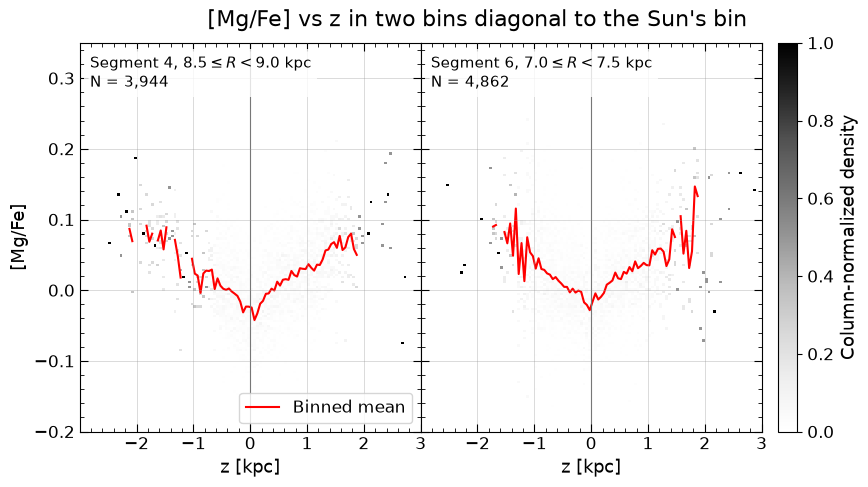

In [3]:
# =============================================================================
# [Mg/Fe] vs z in two bins diagonal to the Sun's bin (uses t from the load cell)
# =============================================================================
from matplotlib.colors import Normalize

# --- choose the bins (segment 1-11, radial range in kpc) ----------------------
BINS = [dict(seg=4, R=(8.5, 9.0)),     # outer galaxy, +Y side of the Sun
        dict(seg=6, R=(7.0, 7.5))]       # inner galaxy, -Y side of the Sun

# --- wedge geometry (same as the analysis code): 180 +/- 45 deg, 11 segments ---
PHI0, HALF_DEG, N_SEG = np.pi, 45.0, 11
seg_bounds = PHI0 - np.deg2rad(HALF_DEG) + np.linspace(0, 2 * np.deg2rad(HALF_DEG), N_SEG + 1)

def in_segment(phi, seg):
    """True where phi lies in segment `seg` (1..11); phi in radians."""
    a, b = seg_bounds[seg - 1], seg_bounds[seg]
    return (phi >= a) & (phi < b)

# --- plot settings -------------------------------------------------------------
Z_LIM, MGFE_LIM = 3.0, (-0.2, 0.35)
DZ, N_MGFE_BINS = 0.05, 160              # z bin width [kpc], [Mg/Fe] bins for the map
MIN_PER_ZBIN = 3                         # need this many stars to draw a mean point

R_all   = np.asarray(t["R_gc_kpc"], float)
phi_all = np.mod(np.asarray(t["phi_gc_rad"], float), 2 * np.pi)   # arctan2 gives [-pi, pi]
z_all   = np.asarray(t["z_gc_kpc"], float)
mgfe_all = np.asarray(t["mgfe"], float)

z_edges = np.arange(-Z_LIM, Z_LIM + DZ / 2, DZ)
z_cent  = 0.5 * (z_edges[:-1] + z_edges[1:])
m_edges = np.linspace(*MGFE_LIM, N_MGFE_BINS + 1)

# --- pass 1: compute the density map and mean line for each bin ----------------
panels = []
for b in BINS:
    R_lo, R_hi = b["R"]
    sel = (in_segment(phi_all, b["seg"]) & (R_all >= R_lo) & (R_all < R_hi)
           & np.isfinite(z_all) & np.isfinite(mgfe_all))
    z, m = z_all[sel], mgfe_all[sel]

    H, _, _ = np.histogram2d(z, m, bins=[z_edges, m_edges])
    colsum = H.sum(axis=1, keepdims=True)
    Hn = np.divide(H, colsum, out=np.zeros_like(H), where=colsum > 0)

    idx = np.digitize(z, z_edges) - 1
    ok = (idx >= 0) & (idx < len(z_cent))
    n_bin = np.bincount(idx[ok], minlength=len(z_cent))
    sum_m = np.bincount(idx[ok], weights=m[ok], minlength=len(z_cent))
    mean = np.where(n_bin >= MIN_PER_ZBIN, sum_m / np.maximum(n_bin, 1), np.nan)

    panels.append(dict(b=b, Hn=Hn, mean=mean, N=int(sel.sum())))
    print(f"segment {b['seg']}, R {R_lo}-{R_hi} kpc: {sel.sum():,} stars")

vmax = max(p["Hn"].max() for p in panels)       # one color scale for all panels

# --- pass 2: plot on shared axes, no gap, one colorbar --------------------------
n = len(panels)
fig, axes = plt.subplots(1, n, figsize=(4.8 * n + 1.0, 4.8),
                         sharex=True, sharey=True,
                         gridspec_kw=dict(wspace=0.0, top=0.92))
axes = np.atleast_1d(axes)

for i, (ax, p) in enumerate(zip(axes, panels)):
    R_lo, R_hi = p["b"]["R"]
    im = ax.pcolormesh(z_edges, m_edges, p["Hn"].T, cmap="Greys",
                       norm=Normalize(vmin=0, vmax=vmax))
    ax.plot(z_cent, p["mean"], color="red", lw=1.5, label="Binned mean" if i == 0 else None)
    ax.axvline(0, color="0.4", lw=0.8)
    ax.set_xlim(-Z_LIM, Z_LIM); ax.set_ylim(*MGFE_LIM)
    ax.set_xlabel("z [kpc]")
    ax.text(0.03, 0.97,
            f"Segment {p['b']['seg']}, ${R_lo:.1f} \\leq R < {R_hi:.1f}$ kpc\nN = {p['N']:,}",
            transform=ax.transAxes, va="top", ha="left", fontsize=11,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
    # drop the leftmost tick on inner panels so labels don't collide at the seam
    ax.set_xticks(np.arange(-Z_LIM, Z_LIM + 1, 1)[(0 if i == 0 else 1):])

from matplotlib.ticker import AutoMinorLocator

for ax in axes:
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which="major", length=6, direction="in", top=True, right=True)
    ax.tick_params(which="minor", length=3, direction="in", top=True, right=True)
    ax.set_axisbelow(False)                      # draw the grid above the density map
    ax.grid(which="major", color="0.6", linestyle="-", linewidth=0.5, alpha=0.5)

axes[0].set_ylabel("[Mg/Fe]")
axes[0].legend(loc="lower right")
fig.suptitle("[Mg/Fe] vs z in two bins diagonal to the Sun's bin", fontsize=16, y=0.99)
fig.colorbar(im, ax=axes.tolist(), pad=0.02).set_label("Column-normalized density")
plt.savefig(FIG_DIR / "mgfe_vs_z_two_bins.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mgfe_vs_z_two_bins.png", dpi=300, bbox_inches="tight")
plt.show()

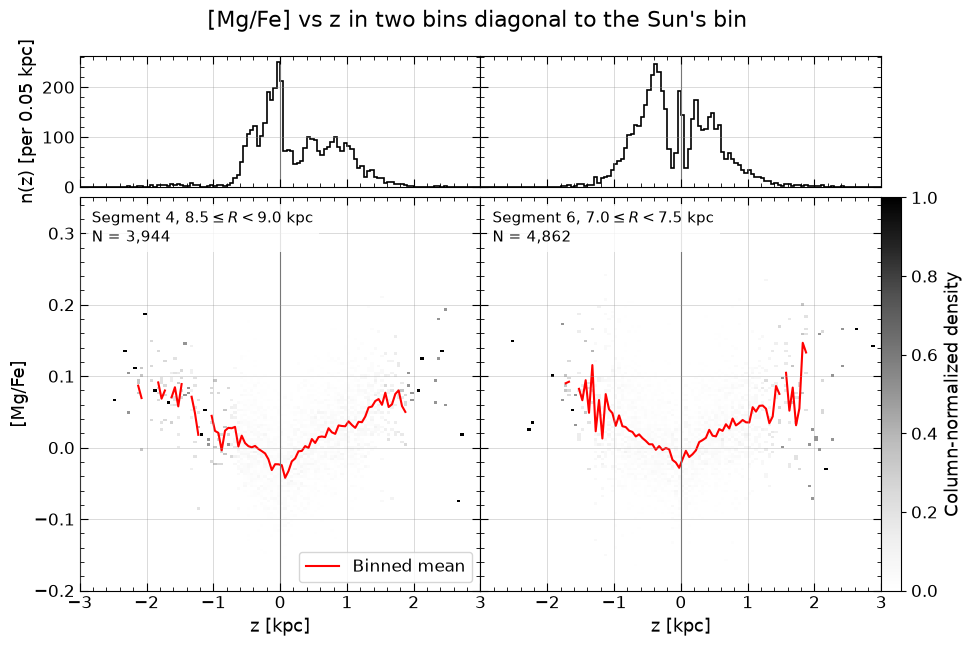

In [32]:
# =============================================================================
# [Mg/Fe] vs z in two bins, with n(z) strip on top (uses t from the load cell)
# =============================================================================
from matplotlib.colors import Normalize
from matplotlib.ticker import AutoMinorLocator

BINS = [dict(seg=4, R=(8.5, 9.0)),
        dict(seg=6, R=(7.0, 7.5))]

PHI0, HALF_DEG, N_SEG = np.pi, 45.0, 11
seg_bounds = PHI0 - np.deg2rad(HALF_DEG) + np.linspace(0, 2 * np.deg2rad(HALF_DEG), N_SEG + 1)

def in_segment(phi, seg):
    a, b = seg_bounds[seg - 1], seg_bounds[seg]
    return (phi >= a) & (phi < b)

Z_LIM, MGFE_LIM = 3.0, (-0.2, 0.35)
DZ, N_MGFE_BINS = 0.05, 160
MIN_PER_ZBIN = 3

R_all    = np.asarray(t["R_gc_kpc"], float)
phi_all  = np.mod(np.asarray(t["phi_gc_rad"], float), 2 * np.pi)
z_all    = np.asarray(t["z_gc_kpc"], float)
mgfe_all = np.asarray(t["mgfe"], float)

z_edges = np.arange(-Z_LIM, Z_LIM + DZ / 2, DZ)
z_cent  = 0.5 * (z_edges[:-1] + z_edges[1:])
m_edges = np.linspace(*MGFE_LIM, N_MGFE_BINS + 1)

# --- pass 1: density map, mean line and n(z) for each bin ----------------------
panels = []
for b in BINS:
    R_lo, R_hi = b["R"]
    sel = (in_segment(phi_all, b["seg"]) & (R_all >= R_lo) & (R_all < R_hi)
           & np.isfinite(z_all) & np.isfinite(mgfe_all))
    z, m = z_all[sel], mgfe_all[sel]

    H, _, _ = np.histogram2d(z, m, bins=[z_edges, m_edges])
    colsum = H.sum(axis=1, keepdims=True)
    Hn = np.divide(H, colsum, out=np.zeros_like(H), where=colsum > 0)

    idx = np.digitize(z, z_edges) - 1
    ok = (idx >= 0) & (idx < len(z_cent))
    n_bin = np.bincount(idx[ok], minlength=len(z_cent))
    sum_m = np.bincount(idx[ok], weights=m[ok], minlength=len(z_cent))
    mean = np.where(n_bin >= MIN_PER_ZBIN, sum_m / np.maximum(n_bin, 1), np.nan)

    panels.append(dict(b=b, Hn=Hn, mean=mean, nz=n_bin, N=int(sel.sum())))

vmax = max(p["Hn"].max() for p in panels)
nmax = max(p["nz"].max() for p in panels)

# --- pass 2: 2 rows x (panels + colorbar column), no gap between panels --------
n = len(panels)
fig = plt.figure(figsize=(4.8 * n + 1.0, 6.6))
gs = fig.add_gridspec(2, n + 1, height_ratios=[1, 3], width_ratios=[1] * n + [0.05],
                      hspace=0.04, wspace=0.0, top=0.92)
ax_top = [fig.add_subplot(gs[0, i]) for i in range(n)]
ax_bot = [fig.add_subplot(gs[1, i]) for i in range(n)]
cax = fig.add_subplot(gs[1, n])

for i, p in enumerate(panels):
    R_lo, R_hi = p["b"]["R"]
    at, ab = ax_top[i], ax_bot[i]

    # top: n(z)
    at.stairs(p["nz"], z_edges, color="k", lw=1.2)
    at.set_ylim(0, 1.05 * nmax)

    # bottom: column-normalized density + binned mean
    im = ab.pcolormesh(z_edges, m_edges, p["Hn"].T, cmap="Greys",
                       norm=Normalize(vmin=0, vmax=vmax))
    ab.plot(z_cent, p["mean"], color="red", lw=1.5, label="Binned mean" if i == 0 else None)
    ab.set_ylim(*MGFE_LIM)
    ab.set_xlabel("z [kpc]")
    ab.text(0.03, 0.97,
            f"Segment {p['b']['seg']}, ${R_lo:.1f} \\leq R < {R_hi:.1f}$ kpc\nN = {p['N']:,}",
            transform=ab.transAxes, va="top", ha="left", fontsize=11,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))

    for a in (at, ab):
        a.axvline(0, color="0.4", lw=0.8)
        a.set_xlim(-Z_LIM, Z_LIM)
        a.set_xticks(np.arange(-Z_LIM, Z_LIM + 1, 1)[(0 if i == 0 else 1):])
        a.xaxis.set_minor_locator(AutoMinorLocator())
        a.yaxis.set_minor_locator(AutoMinorLocator())
        a.tick_params(which="major", length=6, direction="in", top=True, right=True)
        a.tick_params(which="minor", length=3, direction="in", top=True, right=True)
        a.set_axisbelow(False)
        a.grid(which="major", color="0.6", linestyle="-", linewidth=0.5, alpha=0.5)
    at.tick_params(labelbottom=False)
    if i > 0:                                   # shared y on the inner panels
        at.tick_params(labelleft=False)
        ab.tick_params(labelleft=False)

ax_top[0].set_ylabel(f"n(z) [per {DZ:g} kpc]")
ax_bot[0].set_ylabel("[Mg/Fe]")
ax_bot[0].legend(loc="lower right")
fig.colorbar(im, cax=cax).set_label("Column-normalized density")
fig.suptitle("[Mg/Fe] vs z in two bins diagonal to the Sun's bin", fontsize=16, y=0.99)
plt.savefig(FIG_DIR / "mgfe_vs_z_two_bins.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mgfe_vs_z_two_bins.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
# =============================================================================
# Sech2 fits: imports, selection, model, helpers
# =============================================================================
import os, pickle
from itertools import product

import jax
import jax.numpy as jnp
import jax.random as jr
import numpyro
import numpyro.distributions as dist
from numpyro import infer
from scipy.stats import binned_statistic

# --- analysis sample: stars from the saved file, R < 16 kpc, usable [Mg/Fe] error ---
R_MAX_ANALYSIS = 16.0
R_all    = np.asarray(t["R_gc_kpc"], float)
Z_all    = np.asarray(t["z_gc_kpc"], float)
phi_all  = np.mod(np.asarray(t["phi_gc_rad"], float), 2 * np.pi)
mgfe_all = np.asarray(t["mgfe"], float)
err_all  = np.asarray(t["mgfe_err"], float)

use = (np.isfinite(R_all) & np.isfinite(Z_all) & np.isfinite(mgfe_all)
       & np.isfinite(err_all) & (err_all > 0) & (R_all < R_MAX_ANALYSIS))
R_star, Z_star, phi_star = R_all[use], Z_all[use], phi_all[use]
mgfe_star, err_star = mgfe_all[use], err_all[use]
print(f"stars used for the fits: {use.sum():,} of {len(t):,}")

# --- wedge: 180 +/- 45 deg split into 11 segments (same as the analysis code) ---
PHI0, HALF_DEG, N_SEG = np.pi, 45.0, 11
seg_bounds = PHI0 - np.deg2rad(HALF_DEG) + np.linspace(0, 2 * np.deg2rad(HALF_DEG), N_SEG + 1)
segm = {k: (phi_star >= seg_bounds[k - 1]) & (phi_star < seg_bounds[k])
        for k in range(1, N_SEG + 1)}                       # segment k covers [bounds[k-1], bounds[k])
SEGMENTS = list(range(1, N_SEG + 1))

# --- bins and fit requirements (same values as the analysis) ---
R_edges          = np.arange(0.5, 15.5 + 0.5, 0.5)           # 0.5 kpc annuli
Z_BINS_FIT       = np.arange(-5, 5 + 1e-3, 0.1)              # z bins for the binned means
minN_seg_total   = 15      # stars needed in the cell
min_bin_count    = 5       # stars needed in a z bin
min_bins_for_fit = 8       # z bins needed to fit
z_fit_min, z_fit_max = -1.5, 1.5

# --- model: two-component sech^2 dip plus offset ---
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2 + A2 * (1 / jnp.cosh(dz / h2)) ** 2

def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(0.2))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.2))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)
    h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, 0.75))
    h2   = numpyro.deterministic("h2", h1 + d_h2)
    z0     = numpyro.sample("z0",     dist.Normal(0.0, 0.2))
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))
    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset
    Q = numpyro.deterministic("Q", 0.0)
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
                  dist.Normal(model_y, data["mg_fe_err"])]
    numpyro.sample("obs", dist.Mixture(mix, components), obs=data["mg_fe"])

def bin_one(z, mgfe, mgfe_err, z_bins=Z_BINS_FIT):
    """Inverse-variance mean [Mg/Fe] in z bins; error adds the scatter term std/sqrt(N)."""
    s1  = binned_statistic(z, mgfe / mgfe_err**2, bins=z_bins, statistic="sum")
    s2  = binned_statistic(z, 1 / mgfe_err**2,    bins=z_bins, statistic="sum")
    std = binned_statistic(z, mgfe, bins=z_bins, statistic="std")
    cnt = binned_statistic(z, mgfe, bins=z_bins, statistic="count")
    scatter = std.statistic / np.sqrt(cnt.statistic)
    mean = s1.statistic / s2.statistic
    mean_err = np.sqrt(1 / s2.statistic + scatter**2)
    return 0.5 * (z_bins[1:] + z_bins[:-1]), mean, mean_err, cnt.statistic

def fit_sech2(z_binc, mean, err, key, num_warmup=1000, num_samples=1000, num_chains=2):
    sampler = infer.MCMC(
        infer.NUTS(model, dense_mass=True, target_accept_prob=0.95,
                   init_strategy=infer.init_to_median(num_samples=20)),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=False)
    sampler.run(key, data={"z": jnp.asarray(z_binc), "mg_fe": jnp.asarray(mean),
                           "mg_fe_err": jnp.asarray(err)})
    return sampler

def select_cell(seg_mask, Rmin, Rmax):
    """Stars in one (annulus, segment) cell -> binned data, or None if it cannot be fit."""
    m = seg_mask & (R_star >= Rmin) & (R_star < Rmax)
    n = int(m.sum())
    if n < minN_seg_total:
        return None, n
    zc, mean, err, cnt = bin_one(Z_star[m], mgfe_star[m], err_star[m])
    good = (np.isfinite(mean) & np.isfinite(err) & (cnt >= min_bin_count)
            & (zc >= z_fit_min) & (zc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        return None, n
    return (zc[good].astype(float), mean[good].astype(float), err[good].astype(float)), n

stars used for the fits: 334,118 of 345,537


In [7]:
# =============================================================================
# Run the fit in every (radial bin, segment) cell that can be fit (cached)
# =============================================================================
RESULTS_PATH = DATA_DIR / "sech2_fits_final_sample.pkl"
FORCE_RERUN  = False       # True = ignore the saved file and refit everything

n_R = len(R_edges) - 1
if RESULTS_PATH.exists() and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        saved = pickle.load(f)
    z0_med, z0_std = saved["z0_med"], saved["z0_std"]
    n_stars, ok_grid, per_cell = saved["n_stars"], saved["ok_grid"], saved["per_cell"]
    print(f"loaded {RESULTS_PATH.name}: {int(ok_grid.sum())} of {ok_grid.size} cells fit")
else:
    z0_med  = np.full((n_R, N_SEG), np.nan)
    z0_std  = np.full((n_R, N_SEG), np.nan)
    n_stars = np.zeros((n_R, N_SEG), dtype=int)
    ok_grid = np.zeros((n_R, N_SEG), dtype=bool)
    per_cell = {}

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(N_SEG)))
    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        data, n = select_cell(segm[SEGMENTS[j_seg]], Rmin, Rmax)
        n_stars[i_R, j_seg] = n
        if data is not None:
            try:
                key, sub = jr.split(key)
                samples = fit_sech2(*data, sub).get_samples()
                z0_med[i_R, j_seg] = float(np.median(samples["z0"]))
                z0_std[i_R, j_seg] = float(np.std(samples["z0"]))
                ok_grid[i_R, j_seg] = True
                per_cell[(i_R, j_seg)] = {
                    "z_binc": data[0], "mean": data[1], "err": data[2],
                    "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples.items()}}
            except Exception as e:
                print(f"  fit failed: segment {SEGMENTS[j_seg]}, R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 20 == 0 or k == len(pairs):
            print(f"  {k}/{len(pairs)} cells done, {int(ok_grid.sum())} fit so far", flush=True)

    with open(RESULTS_PATH, "wb") as f:
        pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "n_stars": n_stars,
                     "ok_grid": ok_grid, "per_cell": per_cell,
                     "R_edges": R_edges, "seg_bounds": seg_bounds}, f)
    print(f"saved {RESULTS_PATH}")

loaded sech2_fits_final_sample.pkl: 207 of 330 cells fit


saved /Users/emmatasso/outerdisk/figures/sech2_fits_all_bins.pdf and .png  (24 radial bins x 11 segments, 207 fit cells)


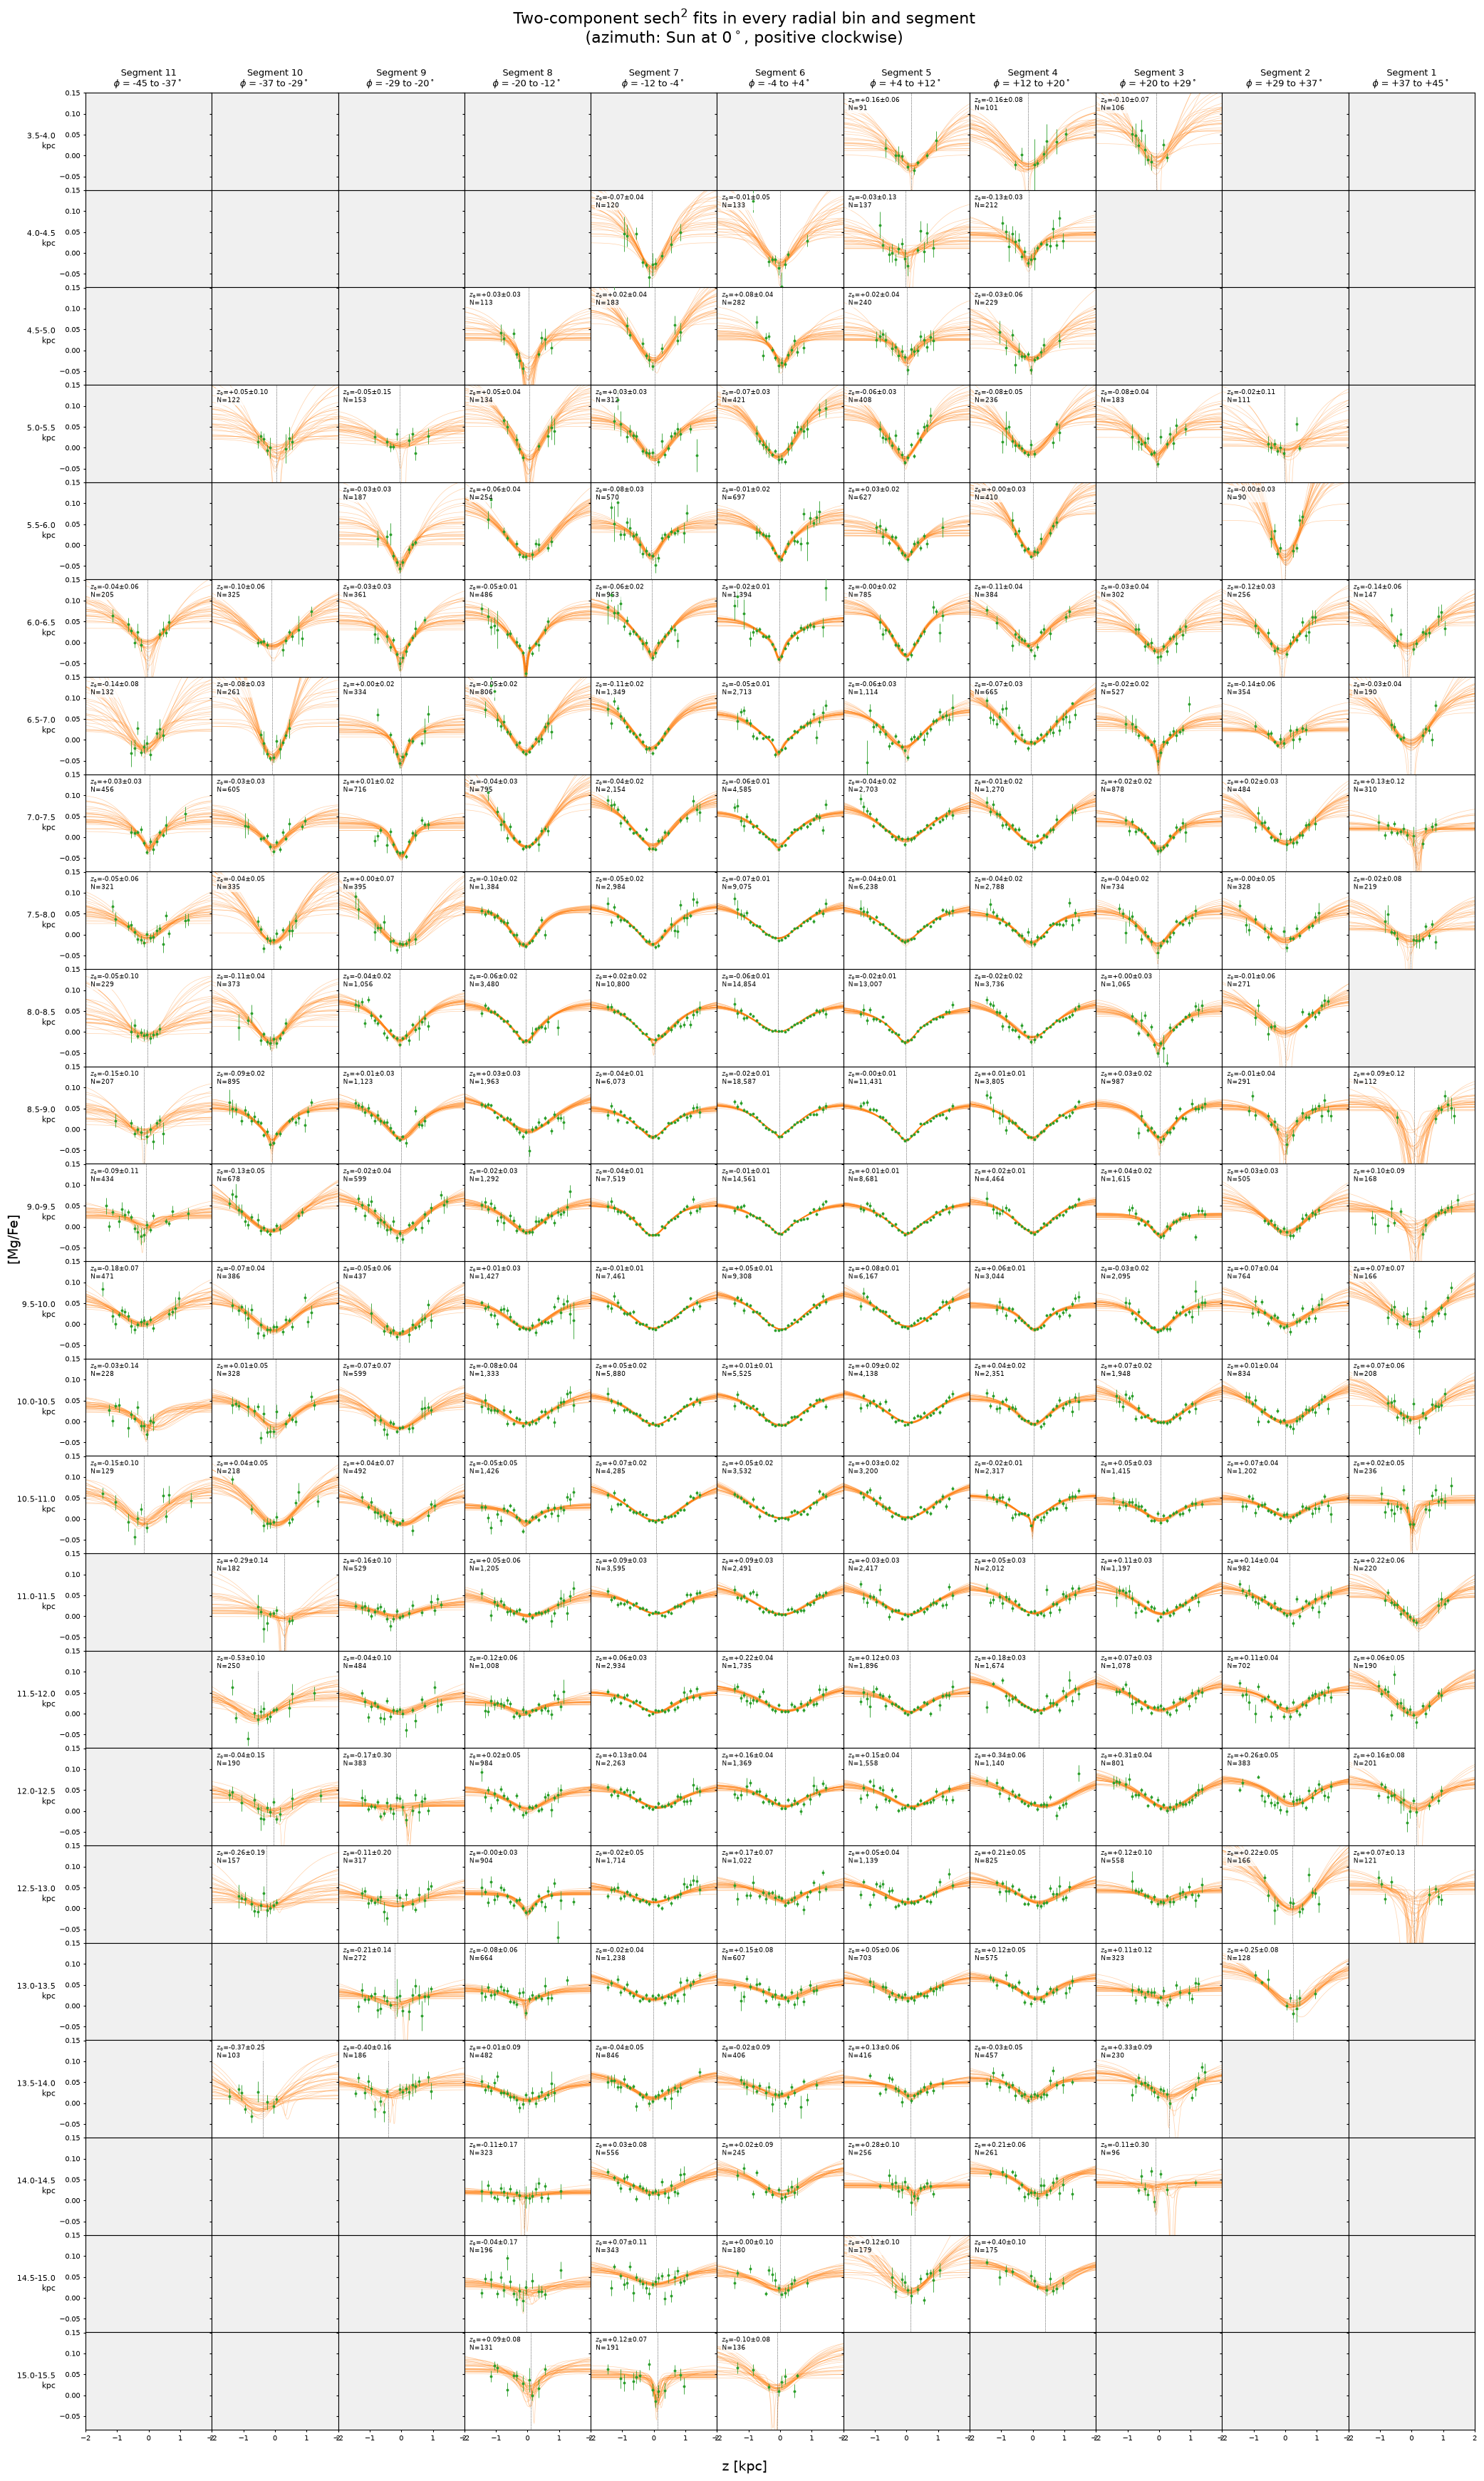

In [8]:
# =============================================================================
# Big figure: every fitted cell, radial bins down the rows, segments across the columns
# Azimuth label convention: Sun at 0 deg, positive clockwise (seen from the north Galactic pole)
# =============================================================================
import matplotlib.pyplot as plt

N_DRAWS       = 30            # posterior draws drawn per panel
Z_PLOT        = 2.0           # x range is +/- this [kpc]
YLIM          = None          # e.g. (-0.1, 0.3); None = set from the data
PANEL_W, PANEL_H = 1.9, 1.45  # inches per panel
FLIP_COLUMNS  = True          # True: columns run by increasing new azimuth (segments 11 -> 1)
OUT_STEM = FIG_DIR / "sech2_fits_all_bins"      # .pdf and .png are added below

def to_sun_frame_deg(phi_rad):
    """Project azimuth (arctan2(y, x), Sun at 180 deg) -> Sun at 0, positive clockwise, in [-180, 180)."""
    d = 180.0 - np.degrees(phi_rad)
    return (d + 180.0) % 360.0 - 180.0

# azimuth range of each segment in the new frame (segment k spans old [b[k-1], b[k]))
seg_hi = to_sun_frame_deg(seg_bounds[:-1])     # new-frame upper edge of segment k
seg_lo = to_sun_frame_deg(seg_bounds[1:])      # new-frame lower edge of segment k

col_order = list(range(N_SEG))[::-1] if FLIP_COLUMNS else list(range(N_SEG))

rows = [i for i in range(n_R) if ok_grid[i].any()]          # radial bins with at least one fit
n_rows = len(rows)

means = np.concatenate([per_cell[k]["mean"] for k in per_cell])
if YLIM is None:
    lo, hi = np.percentile(means, [0.5, 99.5])
    YLIM = (lo - 0.04, hi + 0.06)

zg = np.linspace(-Z_PLOT, Z_PLOT, 200)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(n_rows, N_SEG, figsize=(PANEL_W * N_SEG, PANEL_H * n_rows),
                         sharex=True, sharey=True, squeeze=False,
                         gridspec_kw=dict(hspace=0.0, wspace=0.0))

for r, i_R in enumerate(rows):
    for c_idx, j in enumerate(col_order):
        ax = axes[r, c_idx]
        ax.set_xlim(-Z_PLOT, Z_PLOT); ax.set_ylim(*YLIM)
        ax.tick_params(labelsize=7, length=2)
        if not ok_grid[i_R, j]:
            ax.set_facecolor("0.94")               # cell could not be fit
            continue
        c = per_cell[(i_R, j)]; s = c["samples"]
        for d in rng.choice(len(s["z0"]), N_DRAWS, replace=False):
            y = (mixture_of_sech2(zg, s["A1"][d], s["A2"][d], s["h1"][d], s["h2"][d], s["z0"][d])
                 + s["offset"][d])
            ax.plot(zg, np.asarray(y), color="tab:orange", lw=0.5, alpha=0.35, rasterized=True)
        ax.errorbar(c["z_binc"], c["mean"], yerr=c["err"], fmt="o", ms=1.8, lw=0.6,
                    color="tab:green", zorder=3)
        ax.axvline(z0_med[i_R, j], color="k", lw=0.5, ls=":")
        ax.text(0.04, 0.96, f"$z_0$={z0_med[i_R, j]:+.2f}$\\pm${z0_std[i_R, j]:.2f}\nN={n_stars[i_R, j]:,}",
                transform=ax.transAxes, va="top", ha="left", fontsize=6.5,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

# row labels (radial bin) and column labels (azimuth range in the Sun-at-0 frame)
for r, i_R in enumerate(rows):
    axes[r, 0].set_ylabel(f"{R_edges[i_R]:.1f}-{R_edges[i_R + 1]:.1f}\nkpc",
                          rotation=0, ha="right", va="center", fontsize=8, labelpad=4)
for c_idx, j in enumerate(col_order):
    axes[0, c_idx].set_title(
        f"Segment {SEGMENTS[j]}\n$\\phi$ = {seg_lo[j]:+.0f} to {seg_hi[j]:+.0f}$^\\circ$", fontsize=9)

# margins in inches, so they don't scale with the huge figure height
fig_w, fig_h = PANEL_W * N_SEG, PANEL_H * n_rows
LEFT_IN, RIGHT_IN, BOTTOM_IN, TOP_IN = 1.2, 0.2, 0.7, 1.3
fig.subplots_adjust(left=LEFT_IN / fig_w, right=1 - RIGHT_IN / fig_w,
                    bottom=BOTTOM_IN / fig_h, top=1 - TOP_IN / fig_h,
                    hspace=0.0, wspace=0.0)

fig.supxlabel("z [kpc]", fontsize=14, x=0.5, y=0.08 / fig_h, va="bottom")
fig.supylabel("[Mg/Fe]", fontsize=14, x=0.1 / fig_w, ha="left")
fig.suptitle("Two-component sech$^2$ fits in every radial bin and segment\n"
             "(azimuth: Sun at 0$^\\circ$, positive clockwise)",
             fontsize=16, y=1 - 0.1 / fig_h, va="top")

fig.savefig(OUT_STEM.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM.with_suffix(".png"), dpi=200, bbox_inches="tight")
print(f"saved {OUT_STEM}.pdf and .png  ({n_rows} radial bins x {N_SEG} segments, "
      f"{int(ok_grid.sum())} fit cells)")
plt.show()

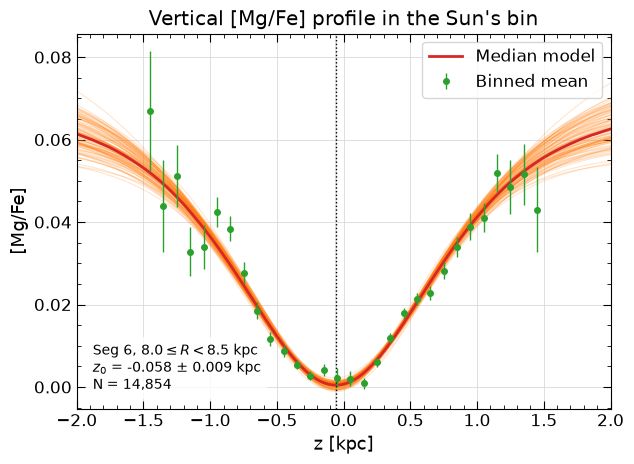

segment 6, R = 8.0-8.5 kpc: 14,854 stars, 30 z bins fit
z0 = -0.058 +/- 0.009 kpc


In [9]:
# =============================================================================
# The Sun's bin on its own: segment 6, 8.0 <= R < 8.5 kpc
# =============================================================================
import matplotlib.pyplot as plt

SEG, R_LO = 6, 8.0
N_DRAWS_ONE = 100
Z_PLOT_ONE  = 2.0
OUT_STEM_SUN = FIG_DIR / "sech2_fit_sun_bin"

j   = SEGMENTS.index(SEG)
i_R = int(np.argmin(np.abs(R_edges - R_LO)))
assert ok_grid[i_R, j], f"segment {SEG}, R={R_LO} was not fit"

c = per_cell[(i_R, j)]; s = c["samples"]
zg = np.linspace(-Z_PLOT_ONE, Z_PLOT_ONE, 400)

# model curve for every posterior sample, shape (n_samples, n_z)
curves = np.asarray(
    mixture_of_sech2(zg[None, :], s["A1"][:, None], s["A2"][:, None],
                     s["h1"][:, None], s["h2"][:, None], s["z0"][:, None])
    + s["offset"][:, None])
rng = np.random.default_rng(0)
draw_idx = rng.choice(len(curves), min(N_DRAWS_ONE, len(curves)), replace=False)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
for d in draw_idx:
    ax.plot(zg, curves[d], color="tab:orange", lw=0.8, alpha=0.2)
ax.plot(zg, np.median(curves, axis=0), color="tab:red", lw=2, label="Median model")
ax.errorbar(c["z_binc"], c["mean"], yerr=c["err"], fmt="o", ms=4, lw=1,
            color="tab:green", zorder=3, label="Binned mean")

z0, dz0 = z0_med[i_R, j], z0_std[i_R, j]
ax.axvline(z0, color="k", lw=1, ls=":")
ax.axvspan(z0 - dz0, z0 + dz0, color="0.5", alpha=0.2, lw=0)

ax.set_xlim(-Z_PLOT_ONE, Z_PLOT_ONE)
ax.set_xlabel("z [kpc]"); ax.set_ylabel("[Mg/Fe]")
ax.set_title("Vertical [Mg/Fe] profile in the Sun's bin")
ax.text(0.03, 0.04,
        f"Seg {SEG}, ${R_edges[i_R]:.1f}\\leq R<{R_edges[i_R + 1]:.1f}$ kpc\n"
        f"$z_0$ = {z0:+.3f} $\\pm$ {dz0:.3f} kpc\n"
        f"N = {n_stars[i_R, j]:,}",
        transform=ax.transAxes, va="bottom", ha="left", fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))

from matplotlib.ticker import AutoMinorLocator

ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(which="major", length=6, direction="in", top=True, right=True)
ax.tick_params(which="minor", length=3, direction="in", top=True, right=True)
ax.grid(which="major", color="0.85", linestyle="-", linewidth=0.6, zorder=0)

ax.legend(loc="upper right")

plt.tight_layout()
fig.savefig(OUT_STEM_SUN.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_SUN.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"segment {SEG}, R = {R_edges[i_R]:.1f}-{R_edges[i_R + 1]:.1f} kpc: "
      f"{n_stars[i_R, j]:,} stars, {len(c['z_binc'])} z bins fit")
print(f"z0 = {z0:+.3f} +/- {dz0:.3f} kpc")

saved /Users/emmatasso/outerdisk/figures/z0_heatmap.pdf and .png  (207 fit cells)


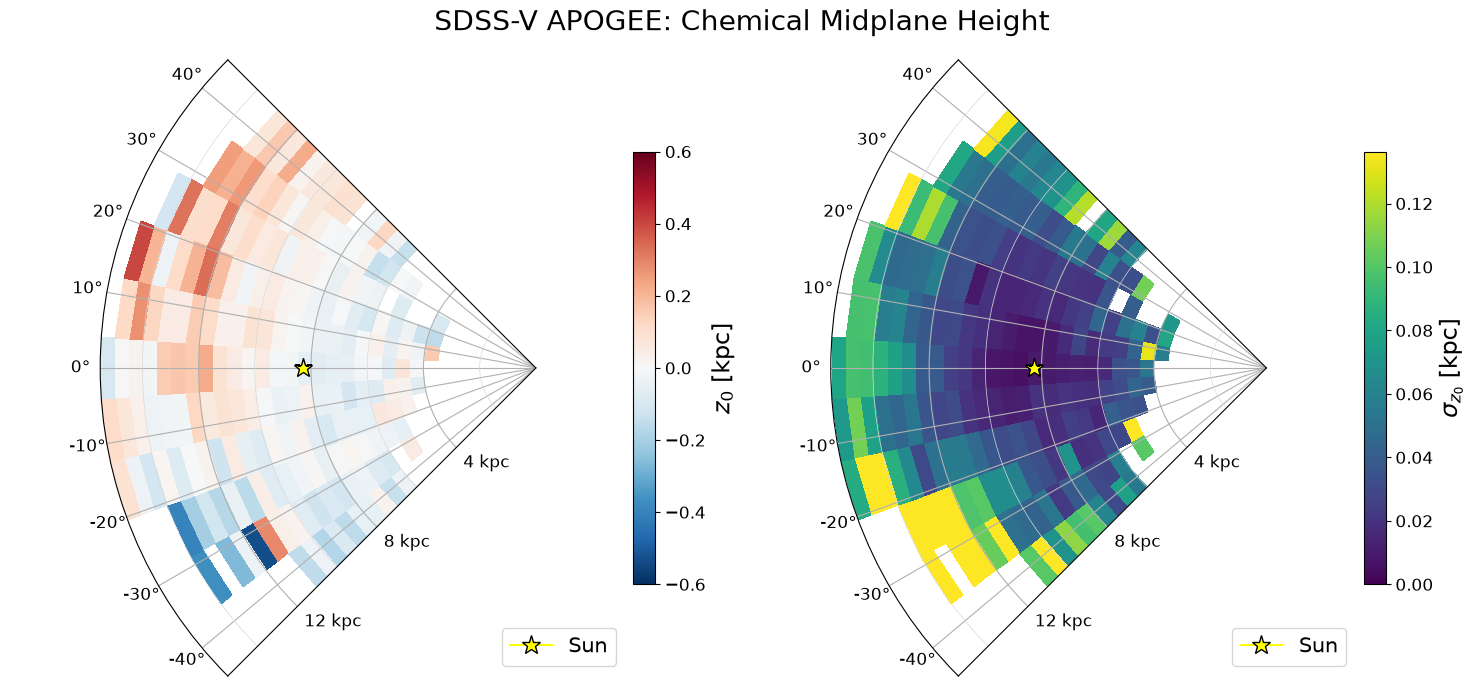

In [10]:
# =============================================================================
# Polar heatmaps of z0 and its uncertainty (Sun at 0 deg, positive clockwise)
# =============================================================================
import matplotlib.pyplot as plt

ZLIM          = 0.6      
OUT_STEM_HEAT = FIG_DIR / "z0_heatmap"

def to_sun_frame_deg(phi_rad):
    """arctan2(y, x) azimuth (Sun at 180 deg) -> Sun at 0, positive clockwise, in [-180, 180)."""
    d = 180.0 - np.degrees(phi_rad)
    return (d + 180.0) % 360.0 - 180.0

# angular bin edges in the new frame, ascending (-45 ... +45 deg)
theta_edges = np.radians(to_sun_frame_deg(seg_bounds)[::-1])

# columns of the grids are segments 1..11 (descending new azimuth), so flip them to match
z0_plot  = z0_med[:, ::-1]
std_plot = z0_std[:, ::-1]

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_plot)
Zmap_std = np.ma.masked_invalid(std_plot)
std_max  = float(np.nanpercentile(std_plot[np.isfinite(std_plot)], 95))

R_TICKS, EXTRA_R_TICKS = [4, 8, 12, 16], [2, 6, 10, 14]
theta_sun, R_sun = 0.0, 8.275

fig = plt.figure(figsize=(15, 7))

def polar_panel(pos, data, cmap, vmin, vmax, label):
    ax = plt.subplot(1, 2, pos, projection="polar")
    pcm = ax.pcolormesh(T_mesh, R_mesh, data, cmap=cmap, vmin=vmin, vmax=vmax, shading="flat")
    fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(label, fontsize=17)
    ax.set_theta_zero_location("W"); ax.set_theta_direction(-1)
    ax.set_rmax(R_edges[-1])
    ax.set_thetamin(np.degrees(theta_edges[0])); ax.set_thetamax(np.degrees(theta_edges[-1]))
    ax.set_rgrids(R_TICKS, labels=[f"{r} kpc" for r in R_TICKS], fontsize=11)
    ax.set_yticks(EXTRA_R_TICKS, minor=True)
    ax.yaxis.grid(True, which="minor", color="0.85", linestyle="-", linewidth=0.5)
    ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
            markeredgecolor="k", zorder=5, label="Sun")
    ax.legend(loc="lower right", fontsize=15)
    return ax

polar_panel(1, Zmap_med, "RdBu_r", -ZLIM, ZLIM, r"$z_0$ [kpc]")
polar_panel(2, Zmap_std, "viridis", 0.0, std_max, r"$\sigma_{z_0}$ [kpc]")
fig.suptitle("SDSS-V APOGEE: Chemical Midplane Height", fontsize=20, y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.tight_layout()
fig.savefig(OUT_STEM_HEAT.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_HEAT.with_suffix(".png"), dpi=300, bbox_inches="tight")
print(f"saved {OUT_STEM_HEAT}.pdf and .png  ({int(ok_grid.sum())} fit cells)")
plt.show()

In [12]:
# =============================================================================
# Sech2 fits in radial bins only (all azimuths combined), for h_eff later
# =============================================================================
from tqdm import tqdm

R_FLARE_LO, R_FLARE_HI, R_WIDTH = 3.5, 15.5, 0.5       # bin width [kpc]
FLARE_EDGES = np.arange(R_FLARE_LO, R_FLARE_HI + 1e-6, R_WIDTH)
n_flare = len(FLARE_EDGES) - 1

WEDGE_ONLY  = False      # True = only stars inside the 11-segment wedge
FLARE_PATH  = DATA_DIR / f"sech2_fits_flare_{R_WIDTH:g}kpc.pkl"
FORCE_RERUN = False

if FLARE_PATH.exists() and not FORCE_RERUN:
    with open(FLARE_PATH, "rb") as f:
        per_R_flare = pickle.load(f)["per_R_flare"]
    print(f"loaded {FLARE_PATH.name}: {len(per_R_flare)} of {n_flare} radial bins fit")
else:
    m_base = (np.isfinite(R_star) & np.isfinite(Z_star) & np.isfinite(mgfe_star)
              & np.isfinite(err_star) & (err_star > 0))
    if WEDGE_ONLY:
        m_base &= (phi_star >= seg_bounds[0]) & (phi_star < seg_bounds[-1])

    per_R_flare = {}
    key = jr.PRNGKey(0)
    for i in tqdm(range(n_flare), desc="fitting radial bins"):
        Rlo, Rhi = float(FLARE_EDGES[i]), float(FLARE_EDGES[i + 1])
        m = m_base & (R_star >= Rlo) & (R_star < Rhi)
        n = int(m.sum())
        if n < minN_seg_total:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipped, only {n} stars")
            continue

        zc, mean, err, cnt = bin_one(Z_star[m], mgfe_star[m], err_star[m])
        good = (np.isfinite(mean) & np.isfinite(err) & (cnt >= min_bin_count)
                & (zc >= z_fit_min) & (zc <= z_fit_max))
        if good.sum() < min_bins_for_fit:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipped, only {int(good.sum())} good z bins")
            continue

        try:
            key, sub = jr.split(key)
            samples = fit_sech2(zc[good].astype(float), mean[good].astype(float),
                                err[good].astype(float), sub).get_samples()
            per_R_flare[i] = {"Rlo": Rlo, "Rhi": Rhi, "n_stars": n,
                              "z_binc": zc[good], "mean": mean[good], "err": err[good],
                              "samples": {k: np.asarray(v) for k, v in samples.items()}}
        except Exception as e:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

    with open(FLARE_PATH, "wb") as f:
        pickle.dump({"per_R_flare": per_R_flare, "flare_edges": FLARE_EDGES}, f)
    print(f"fits complete: {len(per_R_flare)} of {n_flare} bins, saved {FLARE_PATH}")

loaded sech2_fits_flare_0.5kpc.pkl: 24 of 24 radial bins fit


saved /Users/emmatasso/outerdisk/figures/sech2_fits_flare_0.5kpc.pdf and .png  (24 radial bins)


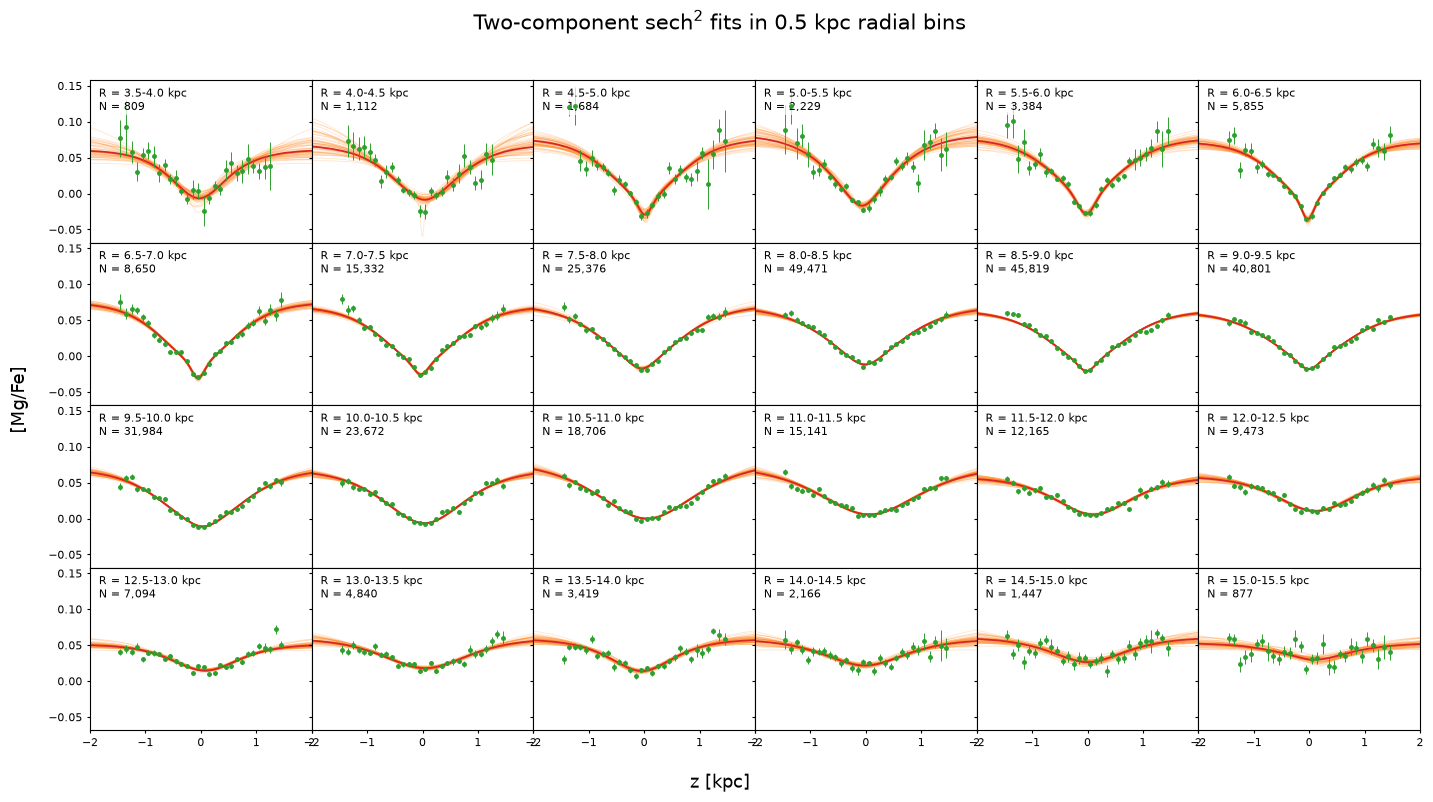

In [13]:
# =============================================================================
# Plot every radial-bin sech2 fit (shared axes)
# =============================================================================
import matplotlib.pyplot as plt

N_COLS        = 6               # panels per row
N_DRAWS       = 50              # posterior draws per panel
Z_PLOT        = 2.0             # x range is +/- this [kpc]
YLIM          = None            # e.g. (-0.1, 0.3); None = set from the data
PANEL_W, PANEL_H = 2.4, 2.0     # inches per panel
OUT_STEM_FLARE = FIG_DIR / f"sech2_fits_flare_{R_WIDTH:g}kpc"

bins = sorted(per_R_flare)
n_panels = len(bins)
n_rows = int(np.ceil(n_panels / N_COLS))

means = np.concatenate([per_R_flare[i]["mean"] for i in bins])
if YLIM is None:
    lo, hi = np.percentile(means, [0.5, 99.5])
    YLIM = (lo - 0.04, hi + 0.06)

zg = np.linspace(-Z_PLOT, Z_PLOT, 300)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(n_rows, N_COLS, figsize=(PANEL_W * N_COLS, PANEL_H * n_rows),
                         sharex=True, sharey=True, squeeze=False,
                         gridspec_kw=dict(hspace=0.0, wspace=0.0))

for k, i in enumerate(bins):
    ax = axes[k // N_COLS, k % N_COLS]
    c = per_R_flare[i]; s = c["samples"]

    # model curve for every posterior sample, shape (n_samples, n_z)
    curves = np.asarray(
        mixture_of_sech2(zg[None, :], s["A1"][:, None], s["A2"][:, None],
                         s["h1"][:, None], s["h2"][:, None], s["z0"][:, None])
        + s["offset"][:, None])
    for d in rng.choice(len(curves), min(N_DRAWS, len(curves)), replace=False):
        ax.plot(zg, curves[d], color="tab:orange", lw=0.6, alpha=0.2, rasterized=True)
    ax.plot(zg, np.median(curves, axis=0), color="tab:red", lw=1.3)
    ax.errorbar(c["z_binc"], c["mean"], yerr=c["err"], fmt="o", ms=2.5, lw=0.7,
                color="tab:green", zorder=3)

    ax.set_xlim(-Z_PLOT, Z_PLOT); ax.set_ylim(*YLIM)
    ax.tick_params(labelsize=8, length=2)
    ax.text(0.04, 0.96, f"R = {c['Rlo']:.1f}-{c['Rhi']:.1f} kpc\nN = {c['n_stars']:,}",
            transform=ax.transAxes, va="top", ha="left", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

for k in range(n_panels, n_rows * N_COLS):          # hide unused panels
    axes[k // N_COLS, k % N_COLS].set_visible(False)

# margins in inches so the labels sit close to the panels
fig_w, fig_h = PANEL_W * N_COLS, PANEL_H * n_rows
fig.subplots_adjust(left=0.9 / fig_w, right=1 - 0.2 / fig_w,
                    bottom=0.7 / fig_h, top=1 - 0.8 / fig_h, hspace=0.0, wspace=0.0)
fig.supxlabel("z [kpc]", fontsize=13, x=0.5, y=0.08 / fig_h, va="bottom")
fig.supylabel("[Mg/Fe]", fontsize=13, x=0.1 / fig_w, ha="left")
fig.suptitle(f"Two-component sech$^2$ fits in {R_WIDTH:g} kpc radial bins",
             fontsize=15, y=1 - 0.1 / fig_h, va="top")

# fig.savefig(OUT_STEM_FLARE.with_suffix(".pdf"), bbox_inches="tight")
# fig.savefig(OUT_STEM_FLARE.with_suffix(".png"), dpi=200, bbox_inches="tight")
print(f"saved {OUT_STEM_FLARE}.pdf and .png  ({n_panels} radial bins)")
plt.show()

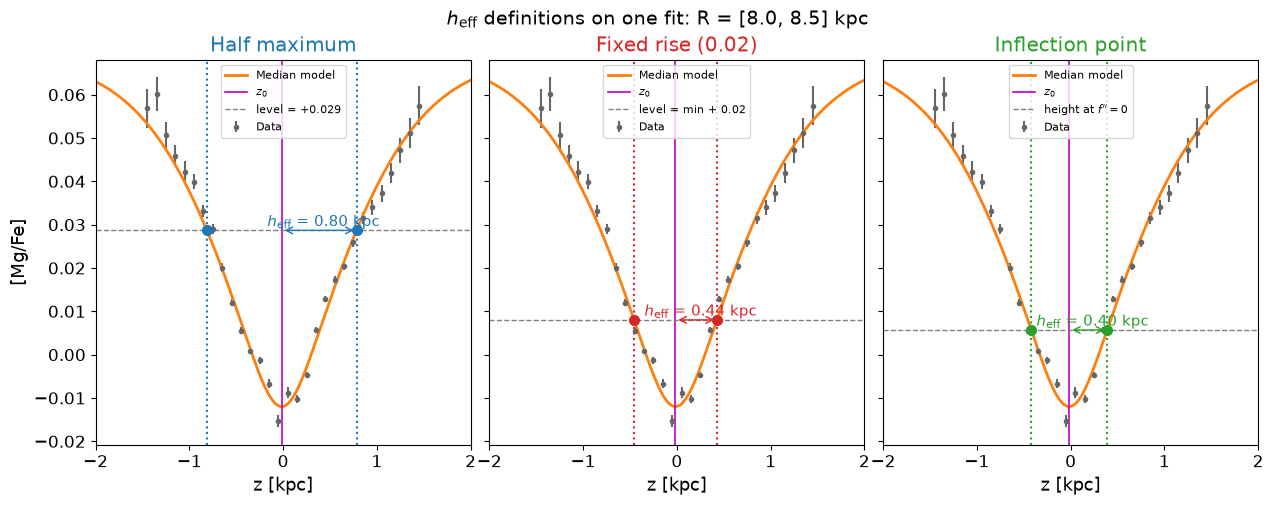

{'half': 0.798, 'fixed': 0.442, 'infl': 0.405}


In [14]:
from scipy.optimize import brentq
import jax
import jax.numpy as jnp

R_TARGET = 8.25     # kpc, center of the radial bin to show (Sun's bin)
DROP     = 0.02    # fixed-rise definition: level = minimum + DROP in [Mg/Fe]

# ---- pick the bin and its median-parameter model ----
i_sel = min(per_R_flare,
            key=lambda i: abs(0.5 * (per_R_flare[i]["Rlo"] + per_R_flare[i]["Rhi"]) - R_TARGET))
cell = per_R_flare[i_sel]
med = {k: float(np.median(v)) for k, v in cell["samples"].items()}
A1, A2, z0, off = med["A1"], med["A2"], med["z0"], med["offset"]
h1, h2 = med["h1"], med["h1"] + med["d_h2"]

def f(z):                      # sech2 mixture without the offset (0 far from the plane)
    return mixture_of_sech2(z, A1, A2, h1, h2, z0)

d2 = jax.grad(jax.grad(lambda z: mixture_of_sech2(z, A1, A2, h1, h2, z0)))   # f''(z)

f_min = A1 + A2                # value of f at z0 (the depth, negative)
levels = {"half": 0.5 * f_min, "fixed": f_min + DROP}

def crossing(level):
    try:
        return brentq(lambda z: float(f(z)) - level, z0 + 1e-9, z0 + 8 * max(h1, h2)) - z0
    except ValueError:
        return np.nan

def inflection():
    for lo, hi in ((z0 + 0.658 * min(h1, h2), z0 + 0.658 * max(h1, h2)),
                   (z0 + 1e-3, z0 + 8 * max(h1, h2))):
        try:
            return brentq(lambda z: float(d2(z)), lo, hi) - z0
        except ValueError:
            continue
    return np.nan

h_eff = {"half": crossing(levels["half"]),
         "fixed": crossing(levels["fixed"]),
         "infl": inflection()}

# ---- figure ----
z_grid = np.linspace(-2, 2, 1000)
y_model = np.asarray(f(z_grid)) + off

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True,
                         gridspec_kw=dict(wspace=0.05))

panels = [
    ("half",  "Half maximum",           "C0", f"level = {levels['half'] + off:+.3f}"),
    ("fixed", f"Fixed rise ({DROP:g})", "C3", f"level = min + {DROP:g}"),
    ("infl",  "Inflection point",       "C2", r"$f''(z)=0$"),
]

for ax, (key, title, color, note) in zip(axes, panels):
    h = h_eff[key]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="0.4", marker=".", linestyle="", label="Data")
    ax.plot(z_grid, y_model, color="C1", lw=2, label="Median model")
    ax.axvline(z0, color="m", lw=1.2, label=r"$z_0$")

    if key in ("half", "fixed"):
        y_pts = levels[key] + off
        ax.axhline(y_pts, color="gray", ls="--", lw=1, label=note)
    else:
        y_pts = float(f(z0 + h)) + off
        ax.axhline(y_pts, color="gray", ls="--", lw=1, label=r"height at $f''=0$")

    for sgn in (-1, 1):
        ax.axvline(z0 + sgn * h, color=color, ls=":", lw=1.5)
    ax.plot([z0 - h, z0 + h], [y_pts, y_pts], "o", color=color, ms=7, zorder=5)
    ax.annotate("", xy=(z0 + h, y_pts), xytext=(z0, y_pts),
                arrowprops=dict(arrowstyle="<->", color=color))
    ax.text(z0 + h / 2, y_pts, f"  $h_\\mathrm{{eff}}$ = {h:.2f} kpc", color=color,
            va="bottom", ha="center", fontsize=11)

    ax.set_title(title, color=color)
    ax.set_xlabel("z [kpc]")
    ax.set_xlim(-2, 2)
    ax.legend(loc="upper center", fontsize=8)

axes[0].set_ylabel("[Mg/Fe]")
fig.suptitle(f"$h_\\mathrm{{eff}}$ definitions on one fit: R = [{cell['Rlo']:.1f}, {cell['Rhi']:.1f}] kpc",
             fontsize=14)
fig.savefig(FIG_DIR / "h_eff_methods_single_fit.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG_DIR / "h_eff_methods_single_fit.pdf", bbox_inches="tight")
plt.show()

print({k: round(v, 3) for k, v in h_eff.items()})

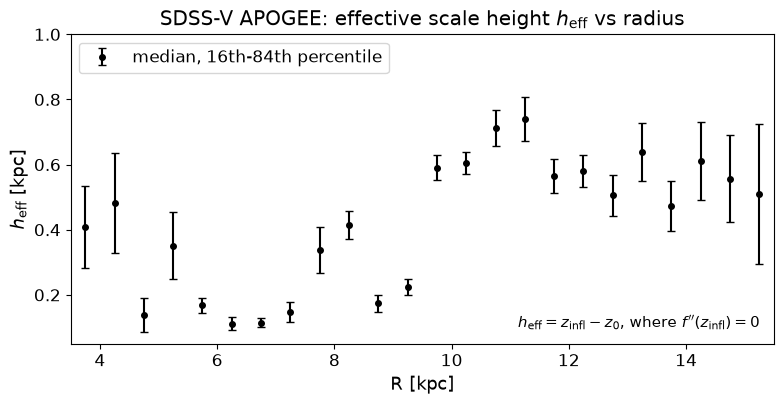

In [15]:
# =============================================================================
# h_eff from the inflection point of the dip: solve d^2 f / dz^2 = 0 for z > z0
# (second derivative from jax.grad(jax.grad(model)), as Adrian suggested)
# =============================================================================
import matplotlib.pyplot as plt

K_INFL = np.arctanh(1 / np.sqrt(3))      # 0.658: inflection of a single sech^2(u)

# second derivative of the actual model with respect to z, vectorized over posterior samples
d2_jax = jax.grad(jax.grad(mixture_of_sech2, argnums=0), argnums=0)
d2_vec = jax.jit(jax.vmap(d2_jax))       # arguments: z, A1, A2, h1, h2, z0 (all arrays)

def inflection_height(s, n_iter=40):
    """h_eff = z_root - z0 for every posterior sample (bisection on f'' from jax.grad)."""
    A1, A2, h1, h2, z0 = (jnp.asarray(np.asarray(s[k])) for k in ("A1", "A2", "h1", "h2", "z0"))
    lo = z0 + K_INFL * h1      # f'' > 0 here
    hi = z0 + K_INFL * h2      # f'' < 0 here (h2 > h1)
    for _ in range(n_iter):
        mid = 0.5 * (lo + hi)
        pos = d2_vec(mid, A1, A2, h1, h2, z0) > 0
        lo = jnp.where(pos, mid, lo)
        hi = jnp.where(pos, hi, mid)
    return np.asarray(0.5 * (lo + hi) - z0)

# --- sanity check: jax second derivative vs the closed form for sech^2 ---
def d2f_analytic(z, A1, A2, h1, h2, z0):
    out = 0.0
    for A, h in ((A1, h1), (A2, h2)):
        t = np.tanh((z - z0) / h)
        out = out + A / h**2 * (1 - t**2) * (6 * t**2 - 2)
    return out

i0 = sorted(per_R_flare)[0]
s0 = {k: float(v[0]) for k, v in per_R_flare[i0]["samples"].items()}
zt = s0["z0"] + 0.3
a = float(d2_jax(zt, s0["A1"], s0["A2"], s0["h1"], s0["h2"], s0["z0"]))
b = float(d2f_analytic(zt, s0["A1"], s0["A2"], s0["h1"], s0["h2"], s0["z0"]))
# print(f"f'' check: jax.grad = {a:.5f}, analytic = {b:.5f}")
assert np.isclose(a, b, rtol=1e-3), "jax and analytic second derivatives disagree"

# --- h_eff in every radial bin, using all posterior samples ---
R_cent = 0.5 * (FLARE_EDGES[:-1] + FLARE_EDGES[1:])
h_eff_med = np.full(n_flare, np.nan)
h_eff_err = np.full(n_flare, np.nan)
h_eff_samples = {}

for i, cell in per_R_flare.items():
    h = inflection_height(cell["samples"])
    h_eff_samples[i] = h
    p16, p50, p84 = np.percentile(h, [16, 50, 84])
    h_eff_med[i], h_eff_err[i] = p50, 0.5 * (p84 - p16)

# print(f"{'R [kpc]':>12s} {'N':>8s} {'h_eff [kpc]':>16s}")
# for i in sorted(per_R_flare):
#     c = per_R_flare[i]
#     print(f"{c['Rlo']:5.1f}-{c['Rhi']:<5.1f} {c['n_stars']:>8,d} "
#           f"{h_eff_med[i]:>9.3f} +/- {h_eff_err[i]:.3f}")

# --- plot ---
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(R_cent, h_eff_med, yerr=h_eff_err, fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_title(r"SDSS-V APOGEE: effective scale height $h_\mathrm{eff}$ vs radius")
ax.text(0.98, 0.04, r"$h_\mathrm{eff} = z_\mathrm{infl} - z_0$, where $f''(z_\mathrm{infl}) = 0$",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=11,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
ax.set_xlim(FLARE_EDGES[0], FLARE_EDGES[-1])
ax.set_ylim(0.05, 1.0)
ax.legend(loc="upper left")
plt.tight_layout()
OUT_STEM_HEFF = FIG_DIR / "h_eff_inflection"
fig.savefig(OUT_STEM_HEFF.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_HEFF.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()

R=15.0-15.5: fixed-rise root exists for only 1619/2000 samples (dip shallower than 0.02 in the rest)
    R [kpc]       inflection         half-max       fixed rise
  3.5-4.0       0.408+/-0.125     0.595+/-0.170     0.401+/-0.094
  4.0-4.5       0.483+/-0.154     0.695+/-0.206     0.432+/-0.106
  4.5-5.0       0.139+/-0.052     0.577+/-0.072     0.188+/-0.049
  5.0-5.5       0.351+/-0.103     0.636+/-0.075     0.310+/-0.041
  5.5-6.0       0.167+/-0.024     0.549+/-0.056     0.200+/-0.019
  6.0-6.5       0.112+/-0.019     0.492+/-0.043     0.148+/-0.019
  6.5-7.0       0.115+/-0.015     0.608+/-0.025     0.186+/-0.020
  7.0-7.5       0.148+/-0.029     0.657+/-0.027     0.257+/-0.024
  7.5-8.0       0.338+/-0.071     0.768+/-0.037     0.385+/-0.022
  8.0-8.5       0.414+/-0.042     0.787+/-0.040     0.439+/-0.014
  8.5-9.0       0.174+/-0.025     0.681+/-0.018     0.311+/-0.014
  9.0-9.5       0.224+/-0.025     0.711+/-0.019     0.359+/-0.012
  9.5-10.0      0.591+/-0.037     0.843+/-0.

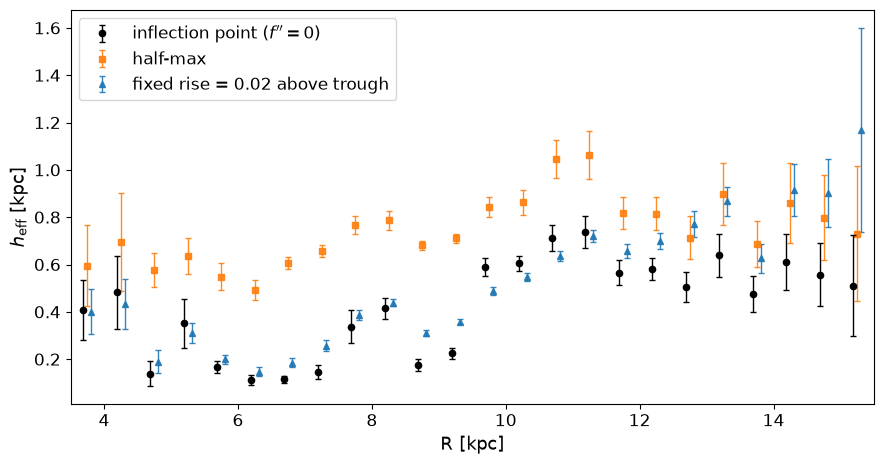

In [16]:
# =============================================================================
# Three h_eff definitions, same posterior samples: inflection, half-max, fixed rise
# =============================================================================
import matplotlib.pyplot as plt

DROP = 0.02          # fixed-rise definition: rise above the trough [dex]; you used 0.025 and 0.015 before

def crossing_height(s, kind, drop=DROP, n_iter=50):
    """z - z0 where the dip profile (no offset) reaches a target level, for every posterior sample.
    kind = "half":  target = half of the dip depth, 0.5 * (A1 + A2)
    kind = "fixed": target = trough + drop, i.e. the profile has risen by `drop` above its minimum
    Samples whose profile never reaches the target return NaN."""
    A1, A2, h1, h2, z0 = (jnp.asarray(np.asarray(s[k])) for k in ("A1", "A2", "h1", "h2", "z0"))
    trough = A1 + A2                                   # profile value at z0 (negative)
    target = 0.5 * trough if kind == "half" else trough + drop

    lo = z0                                            # profile is below target here
    hi = z0 + 8 * jnp.maximum(h1, h2)                  # profile has recovered to ~0 here
    reaches = mixture_of_sech2(hi, A1, A2, h1, h2, z0) > target
    for _ in range(n_iter):                            # the profile rises monotonically for z > z0
        mid = 0.5 * (lo + hi)
        below = mixture_of_sech2(mid, A1, A2, h1, h2, z0) < target
        lo = jnp.where(below, mid, lo)
        hi = jnp.where(below, hi, mid)
    h = np.asarray(0.5 * (lo + hi) - z0)
    return np.where(np.asarray(reaches), h, np.nan)

def summarize(h):
    h = h[np.isfinite(h)]
    if len(h) == 0:
        return np.nan, np.nan, 0
    p16, p50, p84 = np.percentile(h, [16, 50, 84])
    return p50, 0.5 * (p84 - p16), len(h)

h_half_med  = np.full(n_flare, np.nan); h_half_err  = np.full(n_flare, np.nan)
h_fixed_med = np.full(n_flare, np.nan); h_fixed_err = np.full(n_flare, np.nan)
h_half_samples, h_fixed_samples = {}, {}

for i, cell in per_R_flare.items():
    s = cell["samples"]
    h_half_samples[i]  = crossing_height(s, "half")
    h_fixed_samples[i] = crossing_height(s, "fixed")
    h_half_med[i],  h_half_err[i],  _ = summarize(h_half_samples[i])
    h_fixed_med[i], h_fixed_err[i], n_ok = summarize(h_fixed_samples[i])
    if n_ok < 0.9 * len(s["z0"]):
        print(f"R={cell['Rlo']:.1f}-{cell['Rhi']:.1f}: fixed-rise root exists for only "
              f"{n_ok}/{len(s['z0'])} samples (dip shallower than {DROP} in the rest)")

# --- table ---
print(f"{'R [kpc]':>11s} {'inflection':>16s} {'half-max':>16s} {'fixed rise':>16s}")
for i in sorted(per_R_flare):
    c = per_R_flare[i]
    print(f"{c['Rlo']:5.1f}-{c['Rhi']:<5.1f} "
          f"{h_eff_med[i]:>9.3f}+/-{h_eff_err[i]:.3f} "
          f"{h_half_med[i]:>9.3f}+/-{h_half_err[i]:.3f} "
          f"{h_fixed_med[i]:>9.3f}+/-{h_fixed_err[i]:.3f}")

# --- overplot (small horizontal offsets so the error bars don't sit on top of each other) ---
dx = 0.06
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.errorbar(R_cent - dx, h_eff_med, yerr=h_eff_err, fmt="o", lw=1, color="k",
            ms=4.5, capsize=2.5, label="inflection point ($f''=0$)", zorder=3)
ax.errorbar(R_cent, h_half_med, yerr=h_half_err, fmt="s", lw=1, color="tab:orange",
            ms=4.5, capsize=2.5, alpha=0.9, label="half-max", zorder=2)
ax.errorbar(R_cent + dx, h_fixed_med, yerr=h_fixed_err, fmt="^", lw=1, color="tab:blue",
            ms=5, capsize=2.5, alpha=0.9, label=f"fixed rise = {DROP} above trough", zorder=2)
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(FLARE_EDGES[0], FLARE_EDGES[-1])
ax.legend(loc="upper left")
plt.tight_layout()
OUT_STEM_CMP = FIG_DIR / "h_eff_three_definitions"
fig.savefig(OUT_STEM_CMP.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_CMP.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()

In [17]:
# =============================================================================
# Warp model (Adrian's version)
# =============================================================================
import corner
import matplotlib.pyplot as plt
import numpyro
import numpyro.distributions as dist
from numpyro.diagnostics import print_summary
from numpyro.infer import MCMC, NUTS, init_to_value

other_measurements = {
    "Poggio young giants": {"h_w0": 0.012, "R_w": 5.5, "alpha_w": 1.9, "phiLON0": 0.1,
                            "R_t": 12.1, "beta_w": 9.9, "R_range": (9.0, 14.5)},
    "Poggio Cepheids":     {"h_w0": 0.057, "R_w": 7.7, "alpha_w": 1.3, "phiLON0": 0.9,
                            "R_t": 12.6, "beta_w": 8.0, "R_range": (9.0, 16.5)},
}

labels_map = {
    "h_w0": r"$h_{w}(R_\odot)$ [kpc]", "h_w12": r"$h_{w}(12\,{\rm kpc})$ [kpc]",
    "z_off": r"$z_{\rm off}$ [kpc]", "s": r"$s$ [kpc]", "R_w": r"$R_w$ [kpc]",
    "alpha_w": r"$\alpha_w$", "phiLON0": r"$\phi_{\rm LON,0}$ [deg]",
    "R_t": r"$R_t$ [kpc]", "beta_w": r"$\beta_w$ [deg/kpc]",
}

def corner_plot(samples, names=None, color=None, **kwargs):
    kwargs = {"show_titles": True, "quantiles": [0.16, 0.5, 0.84], **kwargs}
    if names is None:
        names = list(samples.keys())
    with plt.rc_context({"figure.constrained_layout.use": False}):
        fig = corner.corner(
            np.stack([samples[k] for k in names], axis=-1),
            labels=[labels_map.get(k, "") for k in names], color=color,
            levels=1 - np.exp(-0.5 * np.array([1.0, 2.0]) ** 2),
            smooth=1.0, bins=40, plot_datapoints=False, fill_contours=True,
            hist_kwargs={"density": True, "lw": 1.5},
            title_fmt=".3g", max_n_ticks=4, **kwargs)

    # left-align the diagonal titles so they extend into the empty upper triangle
    n = len(names)
    axes = np.array(fig.axes).reshape(n, n)
    for i in range(n):
        t = axes[i, i].title
        t.set_ha("left")
        t.set_x(0.0)
    return fig


# Amplitude is normalized at 12 kpc (outside R_w, where the signal is larger),
# which made sampling easier than normalizing at R_sun.
R_norm = 12.0  # kpc
warp_param_names = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w"]

def warp_amp_phase(R, R_w, alpha_w, phiLON0, h_w0, R_t=None, beta_w=None):
    """Warp amplitude A(R) [kpc] and line of nodes phi_LON(R) [deg].
    A(R) = h_w0 [(R - R_w) / (R_norm - R_w)]^alpha_w for R > R_w, 0 otherwise."""
    # the inner where() keeps 0**alpha out of the graph (its gradient wrt alpha is NaN inside R_w)
    ratio = (R - R_w) / (R_norm - R_w)
    A = jnp.where(ratio > 0, h_w0 * jnp.where(ratio > 0, ratio, 1.0) ** alpha_w, 0.0)
    phiLON = phiLON0 + 0.0 * R
    if R_t is not None:
        phiLON = phiLON0 + beta_w * jnp.maximum(R - R_t, 0.0)
    return A, phiLON

def warp_z(R, phi, **params):
    """warp height z = A(R) sin(phi - phiLON(R))"""
    A, phiLON = warp_amp_phase(R, **params)
    return A * jnp.sin(phi - jnp.radians(phiLON))

def poggio_h_w0(samples):
    """convert our amplitude parameter to Poggio's definition."""
    return samples["h_w0"] / (R_norm - samples["R_w"]) ** samples["alpha_w"]

def z_model(R, phi, p):
    """Full model height: m=1 warp + global offset."""
    return warp_z(R, phi, **{k: p[k] for k in warp_param_names if k in p}) + p.get("z_off", 0.0)

def sample_warp_params(twisted=False):
    """Sample the m=1 warp parameters; optionally include the twist."""
    p = {
        "h_w0": numpyro.sample("h_w0", dist.Uniform(1e-4, 2.0)),
        "R_w": numpyro.sample("R_w", dist.Uniform(3.0, R_norm)),
        "alpha_w": numpyro.sample("alpha_w", dist.Uniform(0.1, 5.0)),
        "phiLON0": numpyro.sample("phiLON0", dist.Normal(0, 45.0)),     # deg, weak prior
    }
    if twisted:
        p["R_t"] = numpyro.sample("R_t", dist.Uniform(p["R_w"], 16.0))  # twist starts outside R_w
        p["beta_w"] = numpyro.sample("beta_w", dist.Uniform(-30.0, 30.0))  # deg / kpc
    return p

def warp_model(R, phi, z0_err, z0=None, twisted=False, offset=True, jitter=True, z_off_fixed=None):
    """numpyro model for the warp. z_off_fixed fixes the global offset; offset=True fits it."""
    p = sample_warp_params(twisted=twisted)

    if z_off_fixed is not None:
        p["z_off"] = numpyro.deterministic("z_off", jnp.asarray(z_off_fixed))
    elif offset:
        p["z_off"] = numpyro.sample("z_off", dist.Normal(0.0, 0.1))

    sigma = z0_err
    if jitter:                       # intrinsic scatter of the cell z0 about the smooth model
        s = numpyro.sample("s", dist.HalfNormal(0.1))
        sigma = jnp.sqrt(z0_err**2 + s**2)

    numpyro.sample("z0", dist.Normal(z_model(R, phi, p), sigma), obs=z0)

def run_warp_fit(data, num_warmup=1000, num_samples=2000, seed=0, **model_kwargs):
    """Run NUTS and return posterior samples. data needs keys R, phi, z0, z0_err."""
    init = {"alpha_w": 1.5, "phiLON0": 0.0, "z_off": 0.0, "s": 0.03, "h_w0": 0.3, "R_w": 7.0}
    if model_kwargs.get("twisted", False):
        init.update(R_t=11.0, beta_w=0.0)

    mcmc = MCMC(NUTS(warp_model, init_strategy=init_to_value(values=init)),
                num_warmup=num_warmup, num_samples=num_samples, num_chains=4)
    mcmc.run(jax.random.PRNGKey(seed), **data, **model_kwargs, extra_fields=("diverging",))
    print_summary(mcmc.get_samples(group_by_chain=True))
    print(f"Number of divergences: {mcmc.get_extra_fields()['diverging'].sum()}")
    return {k: np.asarray(v) for k, v in mcmc.get_samples().items()}

In [18]:
# =============================================================================
# Warp data: one point per fitted (radial bin, segment) cell
# =============================================================================
RING_R_MIN, RING_R_MAX = 0.0, 16.0    
MIN_SEG_PER_RING = 3                   

def to_sun_frame_deg(phi_rad):
    """arctan2(y, x) azimuth (Sun at 180 deg) -> Sun at 0, positive clockwise, in [-180, 180)."""
    d = 180.0 - np.degrees(phi_rad)
    return (d + 180.0) % 360.0 - 180.0

seg_centers_old = 0.5 * (seg_bounds[:-1] + seg_bounds[1:])           # one per segment (columns of the grids)
seg_centers_rad = np.radians(to_sun_frame_deg(seg_centers_old))      # Sun-at-0 frame, radians

R_pts, phi_pts, z0_pts, err_pts = [], [], [], []
for i_R in range(len(R_edges) - 1):
    R_c = 0.5 * (R_edges[i_R] + R_edges[i_R + 1])
    if not (RING_R_MIN <= R_c <= RING_R_MAX):
        continue
    ok = (ok_grid[i_R] & np.isfinite(z0_med[i_R]) & np.isfinite(z0_std[i_R]) & (z0_std[i_R] > 0))
    if ok.sum() < MIN_SEG_PER_RING:
        continue
    R_pts.append(np.full(ok.sum(), R_c))
    phi_pts.append(seg_centers_rad[ok])
    z0_pts.append(z0_med[i_R][ok])
    err_pts.append(z0_std[i_R][ok])

warp_data = {"R": np.concatenate(R_pts), "phi": np.concatenate(phi_pts),
             "z0": np.concatenate(z0_pts), "z0_err": np.concatenate(err_pts)}
print(f"{len(warp_data['R'])} cells, R = {warp_data['R'].min():.2f} to {warp_data['R'].max():.2f} kpc, "
      f"phi = {np.degrees(warp_data['phi'].min()):.0f} to {np.degrees(warp_data['phi'].max()):.0f} deg")

207 cells, R = 3.75 to 15.25 kpc, phi = -41 to 41 deg


In [19]:
samples_twist   = run_warp_fit(warp_data, num_warmup=1000, num_samples=8000, seed=0,  twisted=True)
samples_notwist = run_warp_fit(warp_data, num_warmup=1000, num_samples=8000, seed=42, twisted=False)

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_2798/353985347.py:112: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(NUTS(warp_model, init_strategy=init_to_value(values=init)),
sample: 100%|█| 9000/9000 [00:03<00:00, 2535.99it/s, 31 steps of size 7.12e-02. ac
sample: 100%|█| 9000/9000 [00:03<00:00, 2466.26it/s, 127 steps of size 4.24e-02. a
sample: 100%|█| 9000/9000 [00:03<00:00, 2584.41it/s, 63 steps of size 4.92e-02. ac
sample: 100%|█| 9000/9000 [00:02<00:00, 3998.22it/s, 31 steps of size 1.17e-01. ac



                mean       std    median      5.0%     95.0%     n_eff     r_hat
       R_t     11.63      1.98     11.82      8.71     15.99   1751.68      1.00
       R_w      6.54      1.32      6.77      4.34      8.57   3619.81      1.00
   alpha_w      1.60      0.57      1.51      0.70      2.52   2130.99      1.00
    beta_w      4.64      5.77      4.80     -0.32     10.83   2722.07      1.00
      h_w0      0.24      0.02      0.24      0.20      0.27  15068.04      1.00
   phiLON0    -30.57      7.64    -29.52    -42.38    -19.18   3746.28      1.00
         s      0.04      0.00      0.04      0.03      0.05   6908.72      1.00
     z_off     -0.04      0.01     -0.04     -0.05     -0.03   6874.76      1.00

Number of divergences: 121


sample: 100%|█| 9000/9000 [00:02<00:00, 4397.45it/s, 15 steps of size 2.13e-01. ac
sample: 100%|█| 9000/9000 [00:01<00:00, 6587.64it/s, 31 steps of size 1.91e-01. ac
sample: 100%|█| 9000/9000 [00:01<00:00, 6026.94it/s, 15 steps of size 1.45e-01. ac
sample: 100%|█| 9000/9000 [00:01<00:00, 6073.33it/s, 31 steps of size 1.47e-01. ac


                mean       std    median      5.0%     95.0%     n_eff     r_hat
       R_w      7.12      1.11      7.38      5.47      8.70   8100.39      1.00
   alpha_w      1.16      0.41      1.08      0.54      1.76   8265.89      1.00
      h_w0      0.24      0.02      0.24      0.20      0.27  14785.85      1.00
   phiLON0    -22.38      3.56    -22.22    -28.29    -16.66  11724.12      1.00
         s      0.04      0.00      0.04      0.03      0.05  16598.90      1.00
     z_off     -0.03      0.01     -0.03     -0.05     -0.02  16725.78      1.00

Number of divergences: 20



twisted line of nodes
parameter     median    -1sig    +1sig  Poggio YG
h_w0           0.020    0.016    0.033      0.012
R_w            6.766    1.636    1.090        5.5
alpha_w        1.511    0.467    0.694        1.9
phiLON0      -29.522    7.682    5.880        0.1
R_t           11.816    2.188    1.321       12.1
beta_w         4.801    2.291    2.428        9.9
z_off         -0.037    0.007    0.007           
s              0.039    0.004    0.004           

no twist
parameter     median    -1sig    +1sig  Poggio YG
h_w0           0.045    0.029    0.035      0.012
R_w            7.377    1.258    0.735        5.5
alpha_w        1.084    0.296    0.454        1.9
phiLON0      -22.221    3.698    3.375        0.1
z_off         -0.035    0.006    0.006           
s              0.040    0.004    0.004           


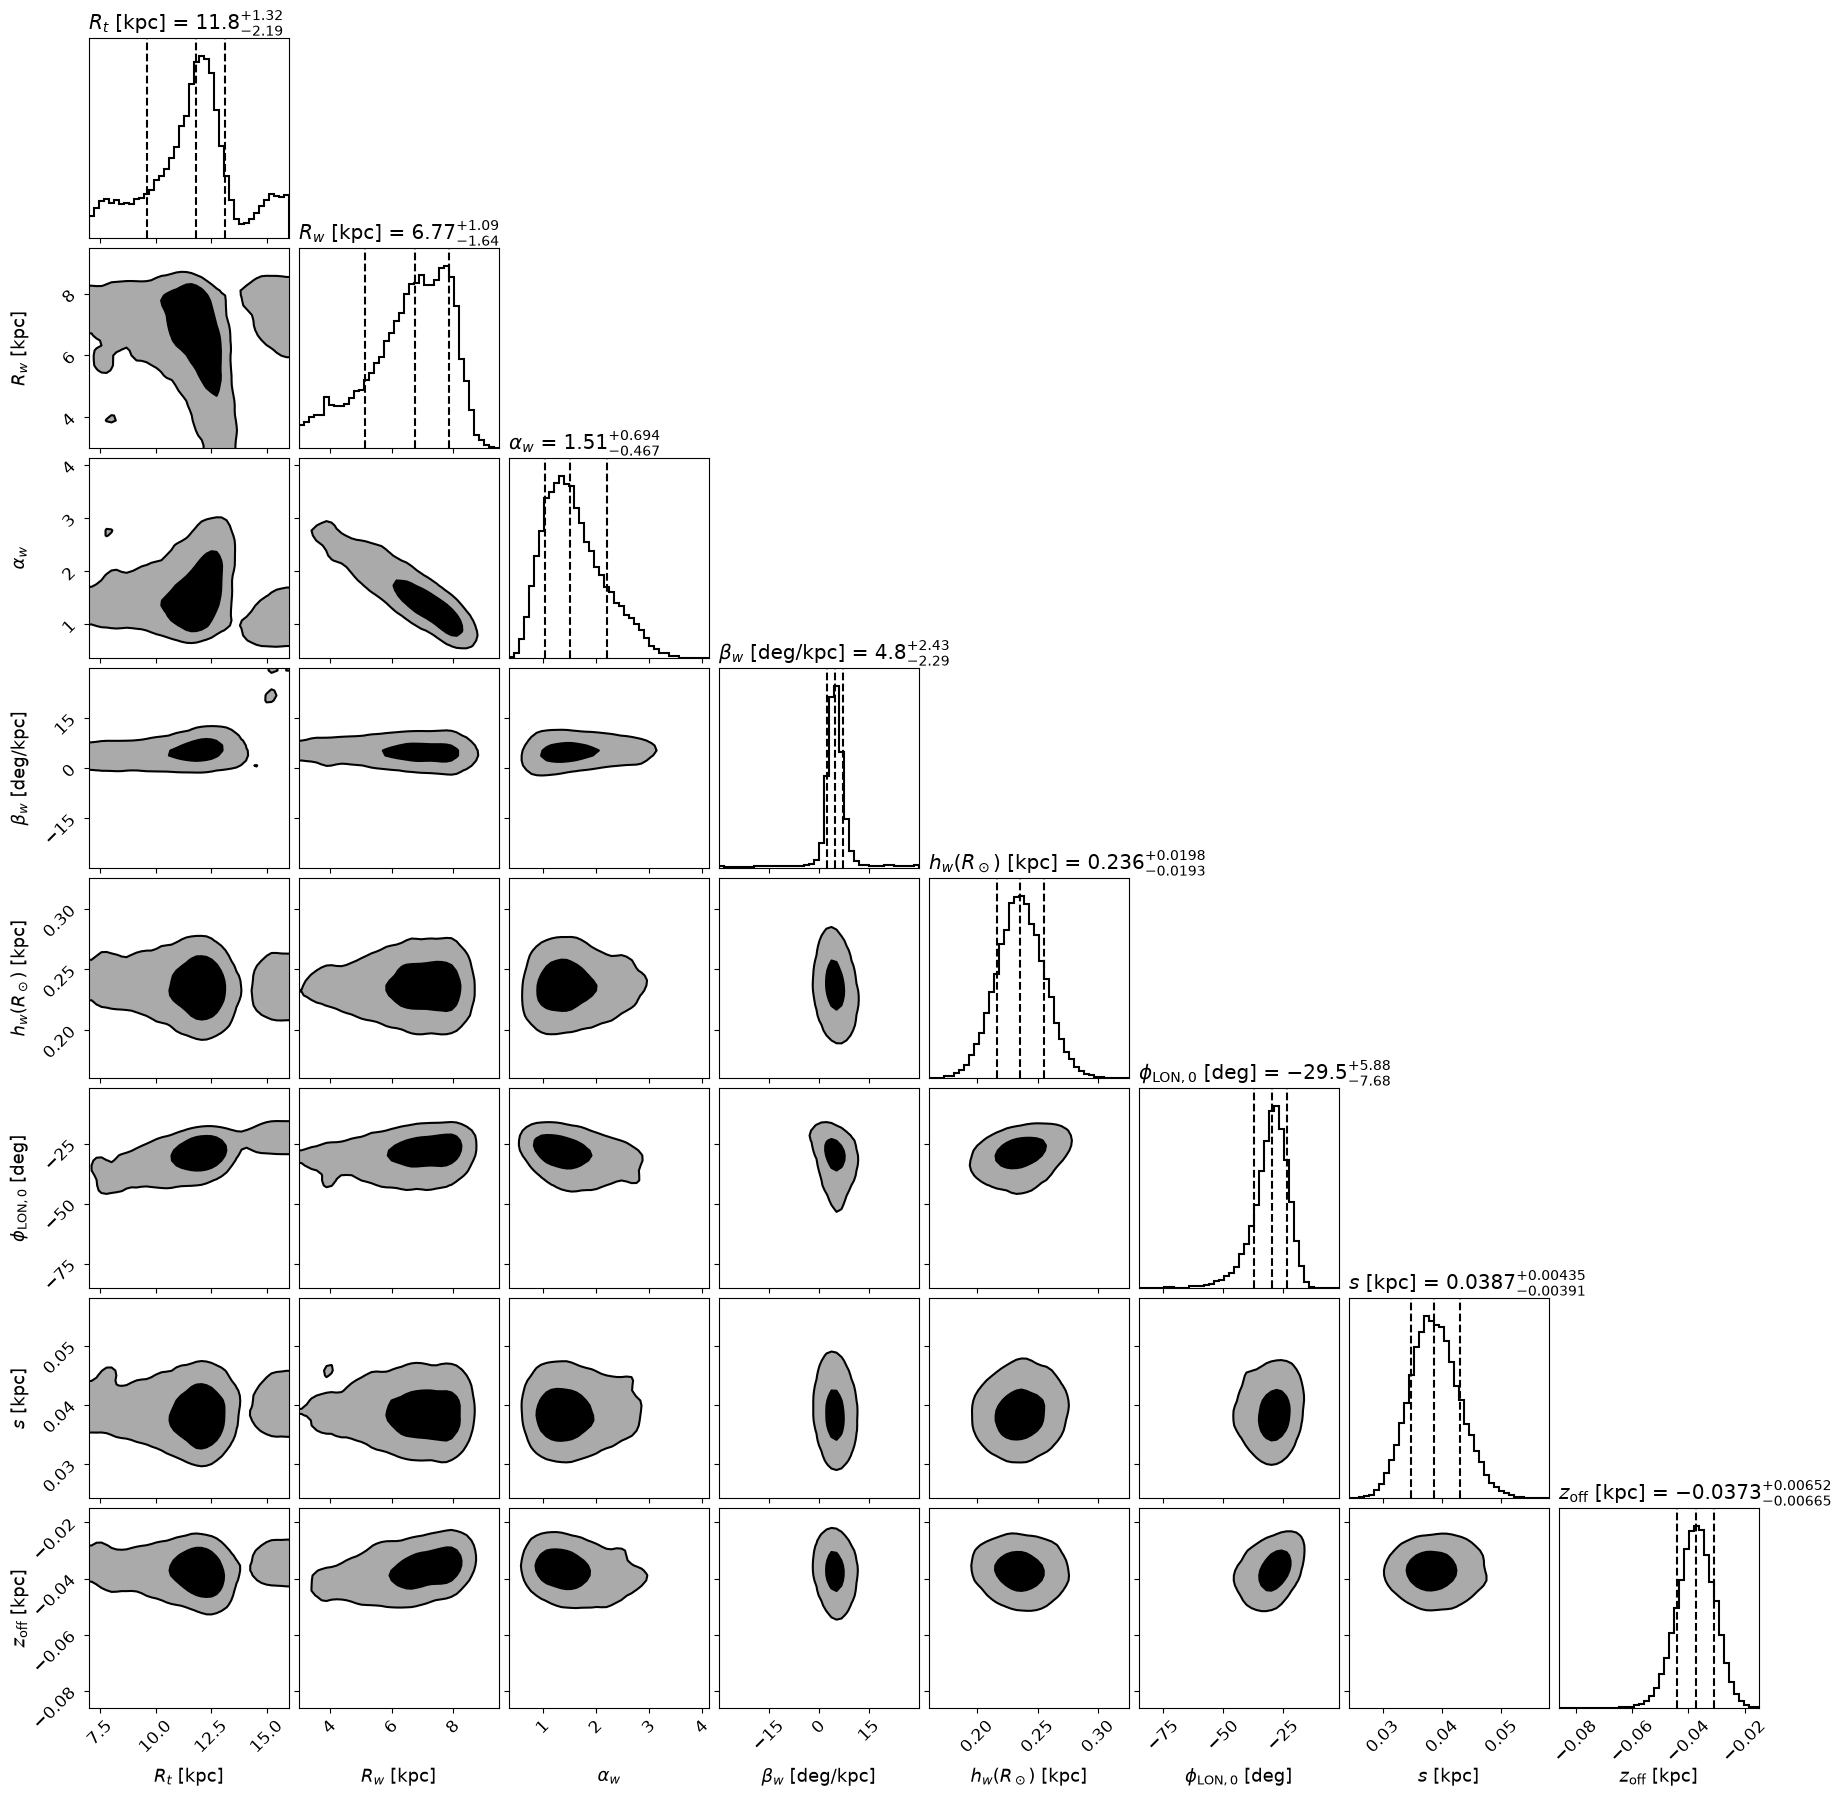

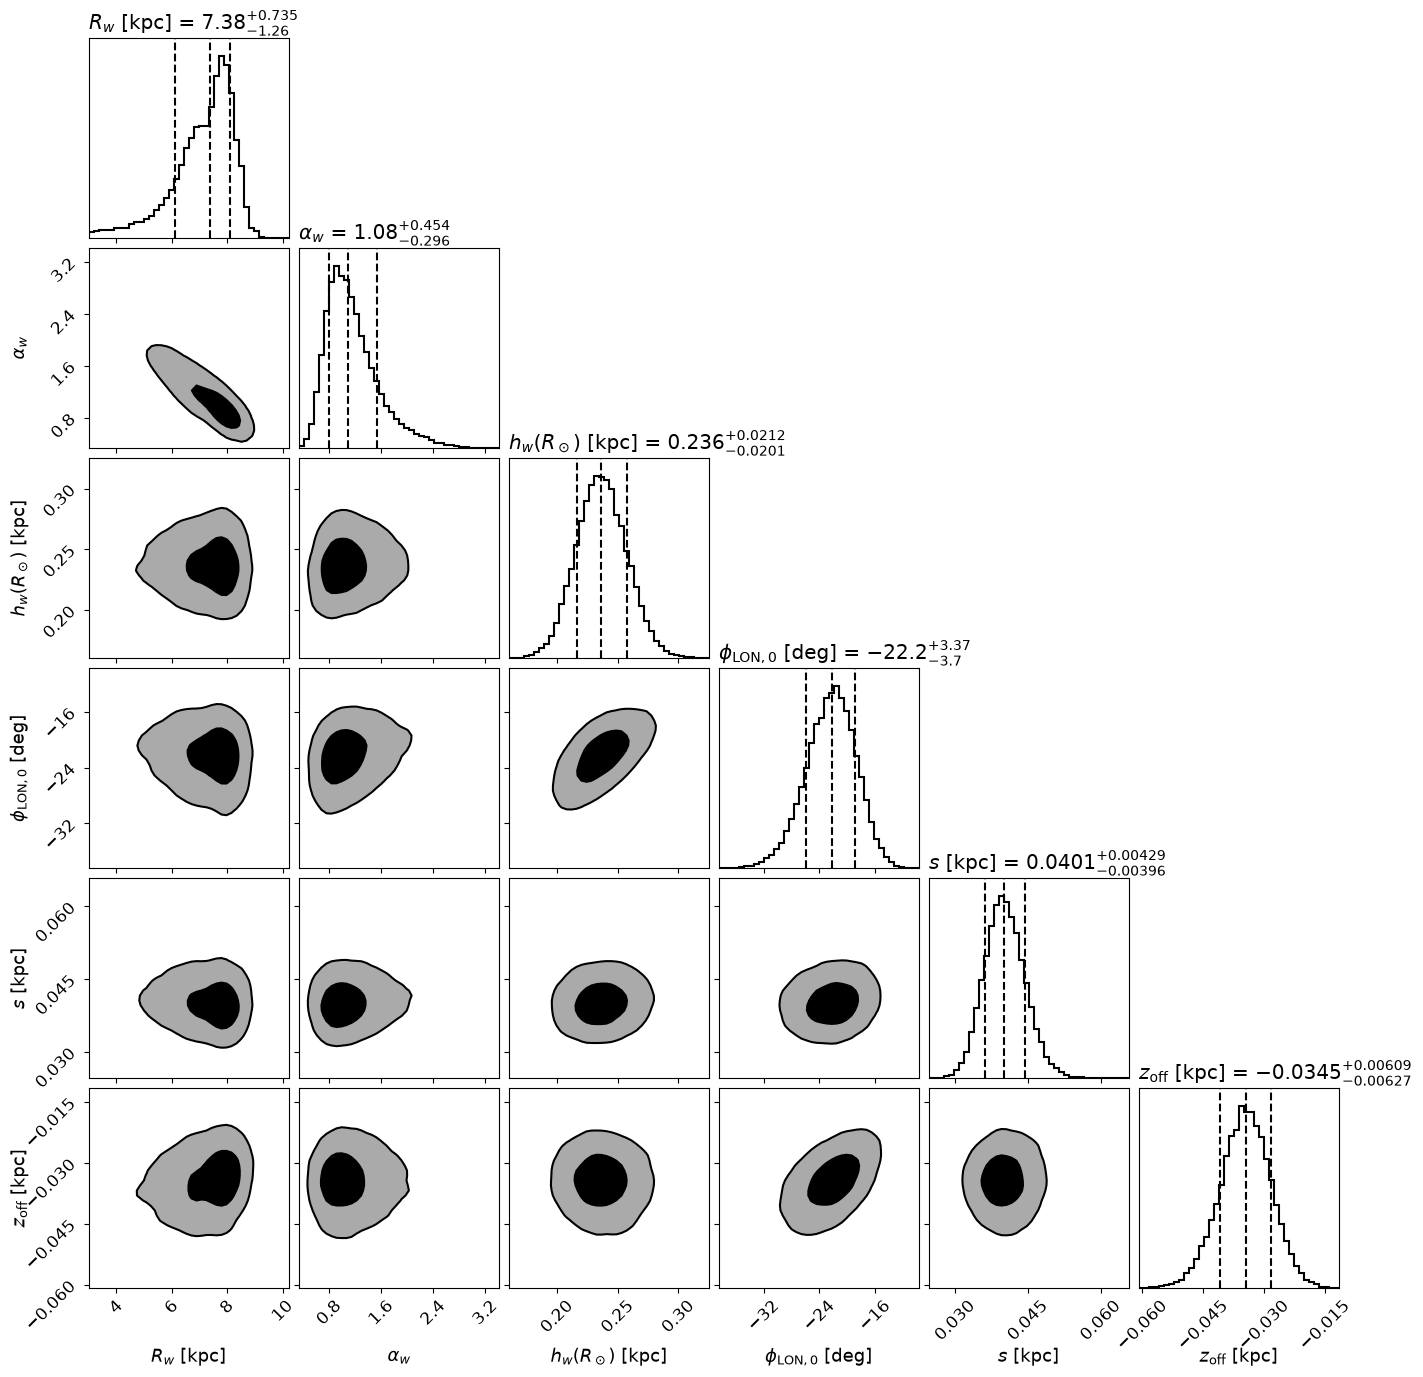

In [20]:
# --- parameter summary, with Poggio young giants for comparison ---
pg = other_measurements["Poggio young giants"]

def summarize_warp(samples, label):
    print(f"\n{label}")
    print(f"{'parameter':<10s} {'median':>9s} {'-1sig':>8s} {'+1sig':>8s} {'Poggio YG':>10s}")
    rows = dict(samples)
    rows["h_w0"] = poggio_h_w0(samples)          # amplitude in Poggio's definition
    for k in ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w", "z_off", "s"]:
        if k not in rows:
            continue
        lo, med, hi = np.percentile(rows[k], [16, 50, 84])
        ref = f"{pg[k]:>10.3g}" if k in pg else f"{'':>10s}"
        print(f"{k:<10s} {med:>9.3f} {med - lo:>8.3f} {hi - med:>8.3f} {ref}")

summarize_warp(samples_twist,   "twisted line of nodes")
summarize_warp(samples_notwist, "no twist")

# --- corner plots (parameters as sampled, h_w0 = amplitude at 12 kpc) ---
fig_t = corner_plot(samples_twist)
fig_t.savefig(FIG_DIR / "warp_corner_twist.png", dpi=200, bbox_inches="tight")
fig_n = corner_plot(samples_notwist)
fig_n.savefig(FIG_DIR / "warp_corner_notwist.png", dpi=200, bbox_inches="tight")
plt.show()

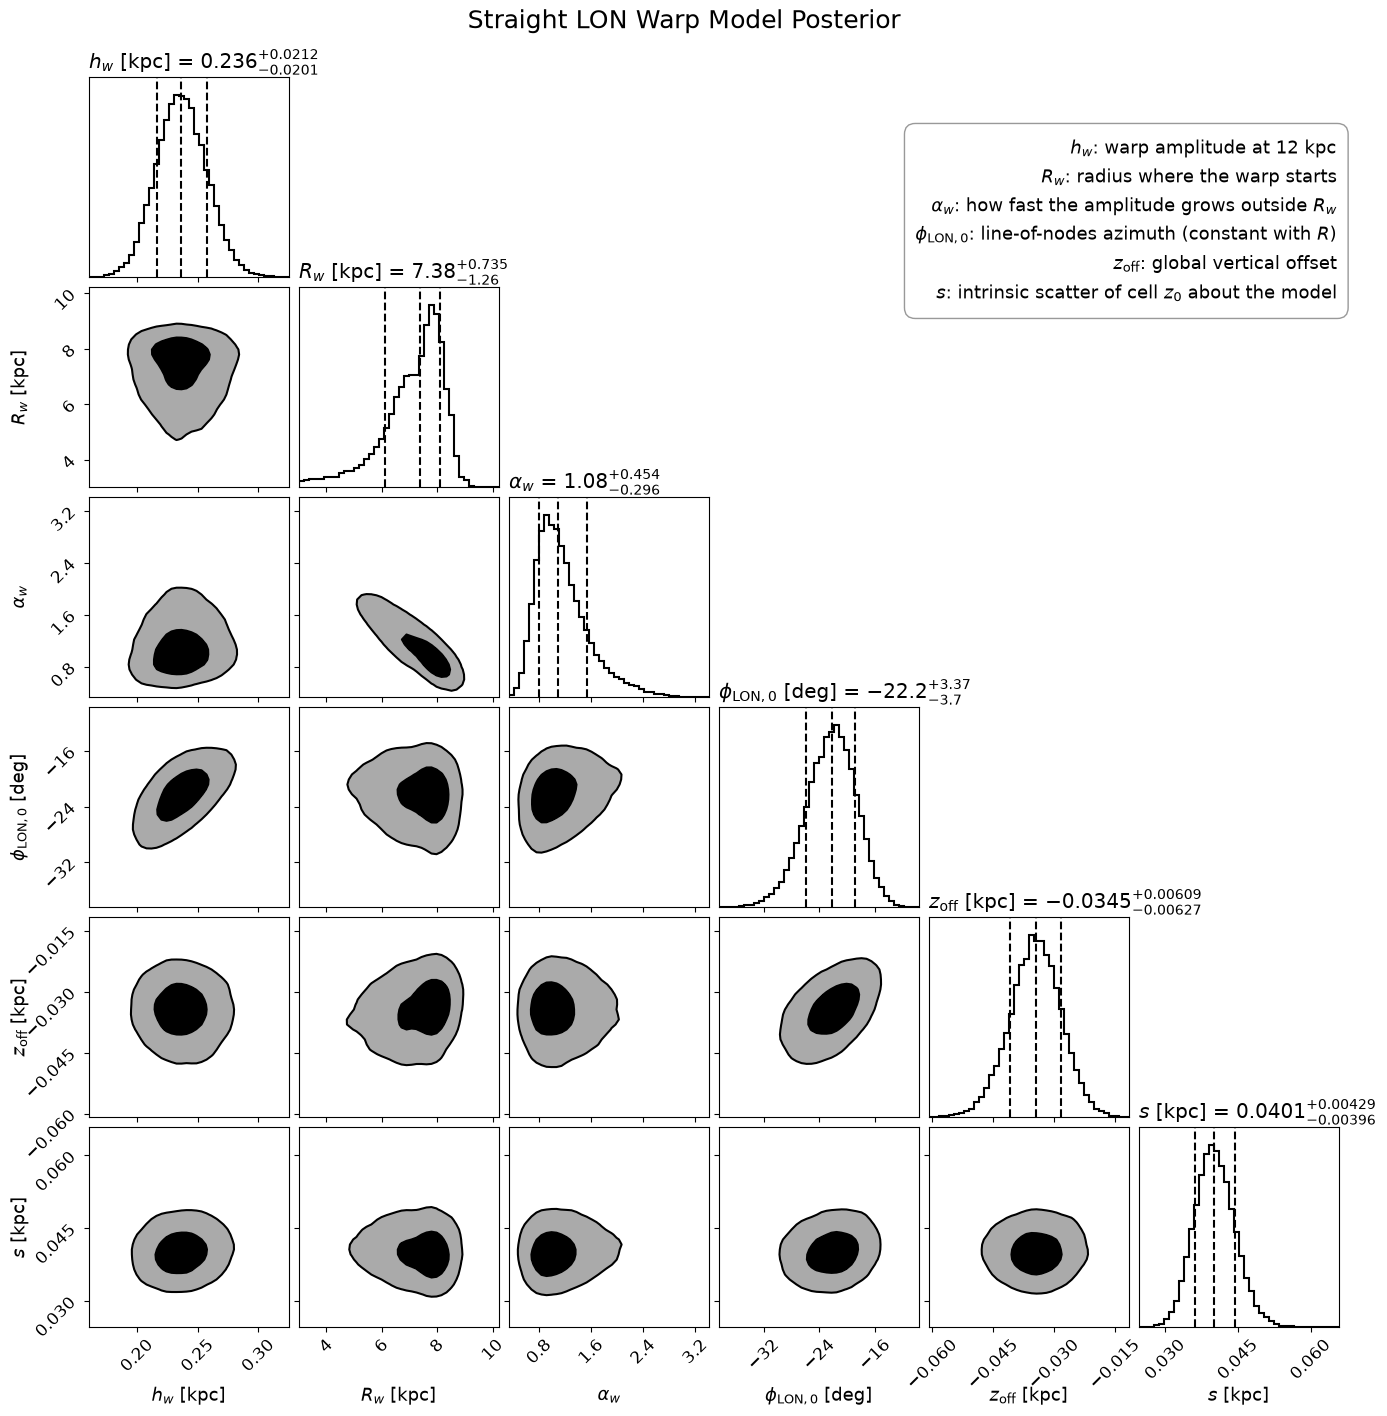

In [21]:
# --- straight line-of-nodes corner plot with title and parameter legend ---
labels_map["h_w0"] = r"$h_{w}\ [{\rm kpc}]$"
names_n = ["h_w0", "R_w", "alpha_w", "phiLON0", "z_off", "s"]

fig_n = corner_plot(samples_notwist, names=names_n)
fig_n.suptitle("Straight LON Warp Model Posterior", fontsize=18, y=1.02)

legend_text_n = "\n".join([
    r"$h_w$: warp amplitude at 12 kpc",
    r"$R_w$: radius where the warp starts",
    r"$\alpha_w$: how fast the amplitude grows outside $R_w$",
    r"$\phi_{\rm LON,0}$: line-of-nodes azimuth (constant with $R$)",
    r"$z_{\rm off}$: global vertical offset",
    r"$s$: intrinsic scatter of cell $z_0$ about the model",
])
fig_n.text(0.97, 0.93, legend_text_n, ha="right", va="top", fontsize=13, linespacing=1.6,
           bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="0.6"))

fig_n.savefig(FIG_DIR / "warp_corner_notwist.png", dpi=200, bbox_inches="tight")
fig_n.savefig(FIG_DIR / "warp_corner_notwist.pdf", bbox_inches="tight")
plt.show()


twisted line of nodes
parameter     median    -1sig    +1sig  Poggio YG
h_w0           0.020    0.016    0.033      0.012
R_w            6.766    1.636    1.090        5.5
alpha_w        1.511    0.467    0.694        1.9
phiLON0      -29.522    7.682    5.880        0.1
R_t           11.816    2.188    1.321       12.1
beta_w         4.801    2.291    2.428        9.9
z_off         -0.037    0.007    0.007           
s              0.039    0.004    0.004           


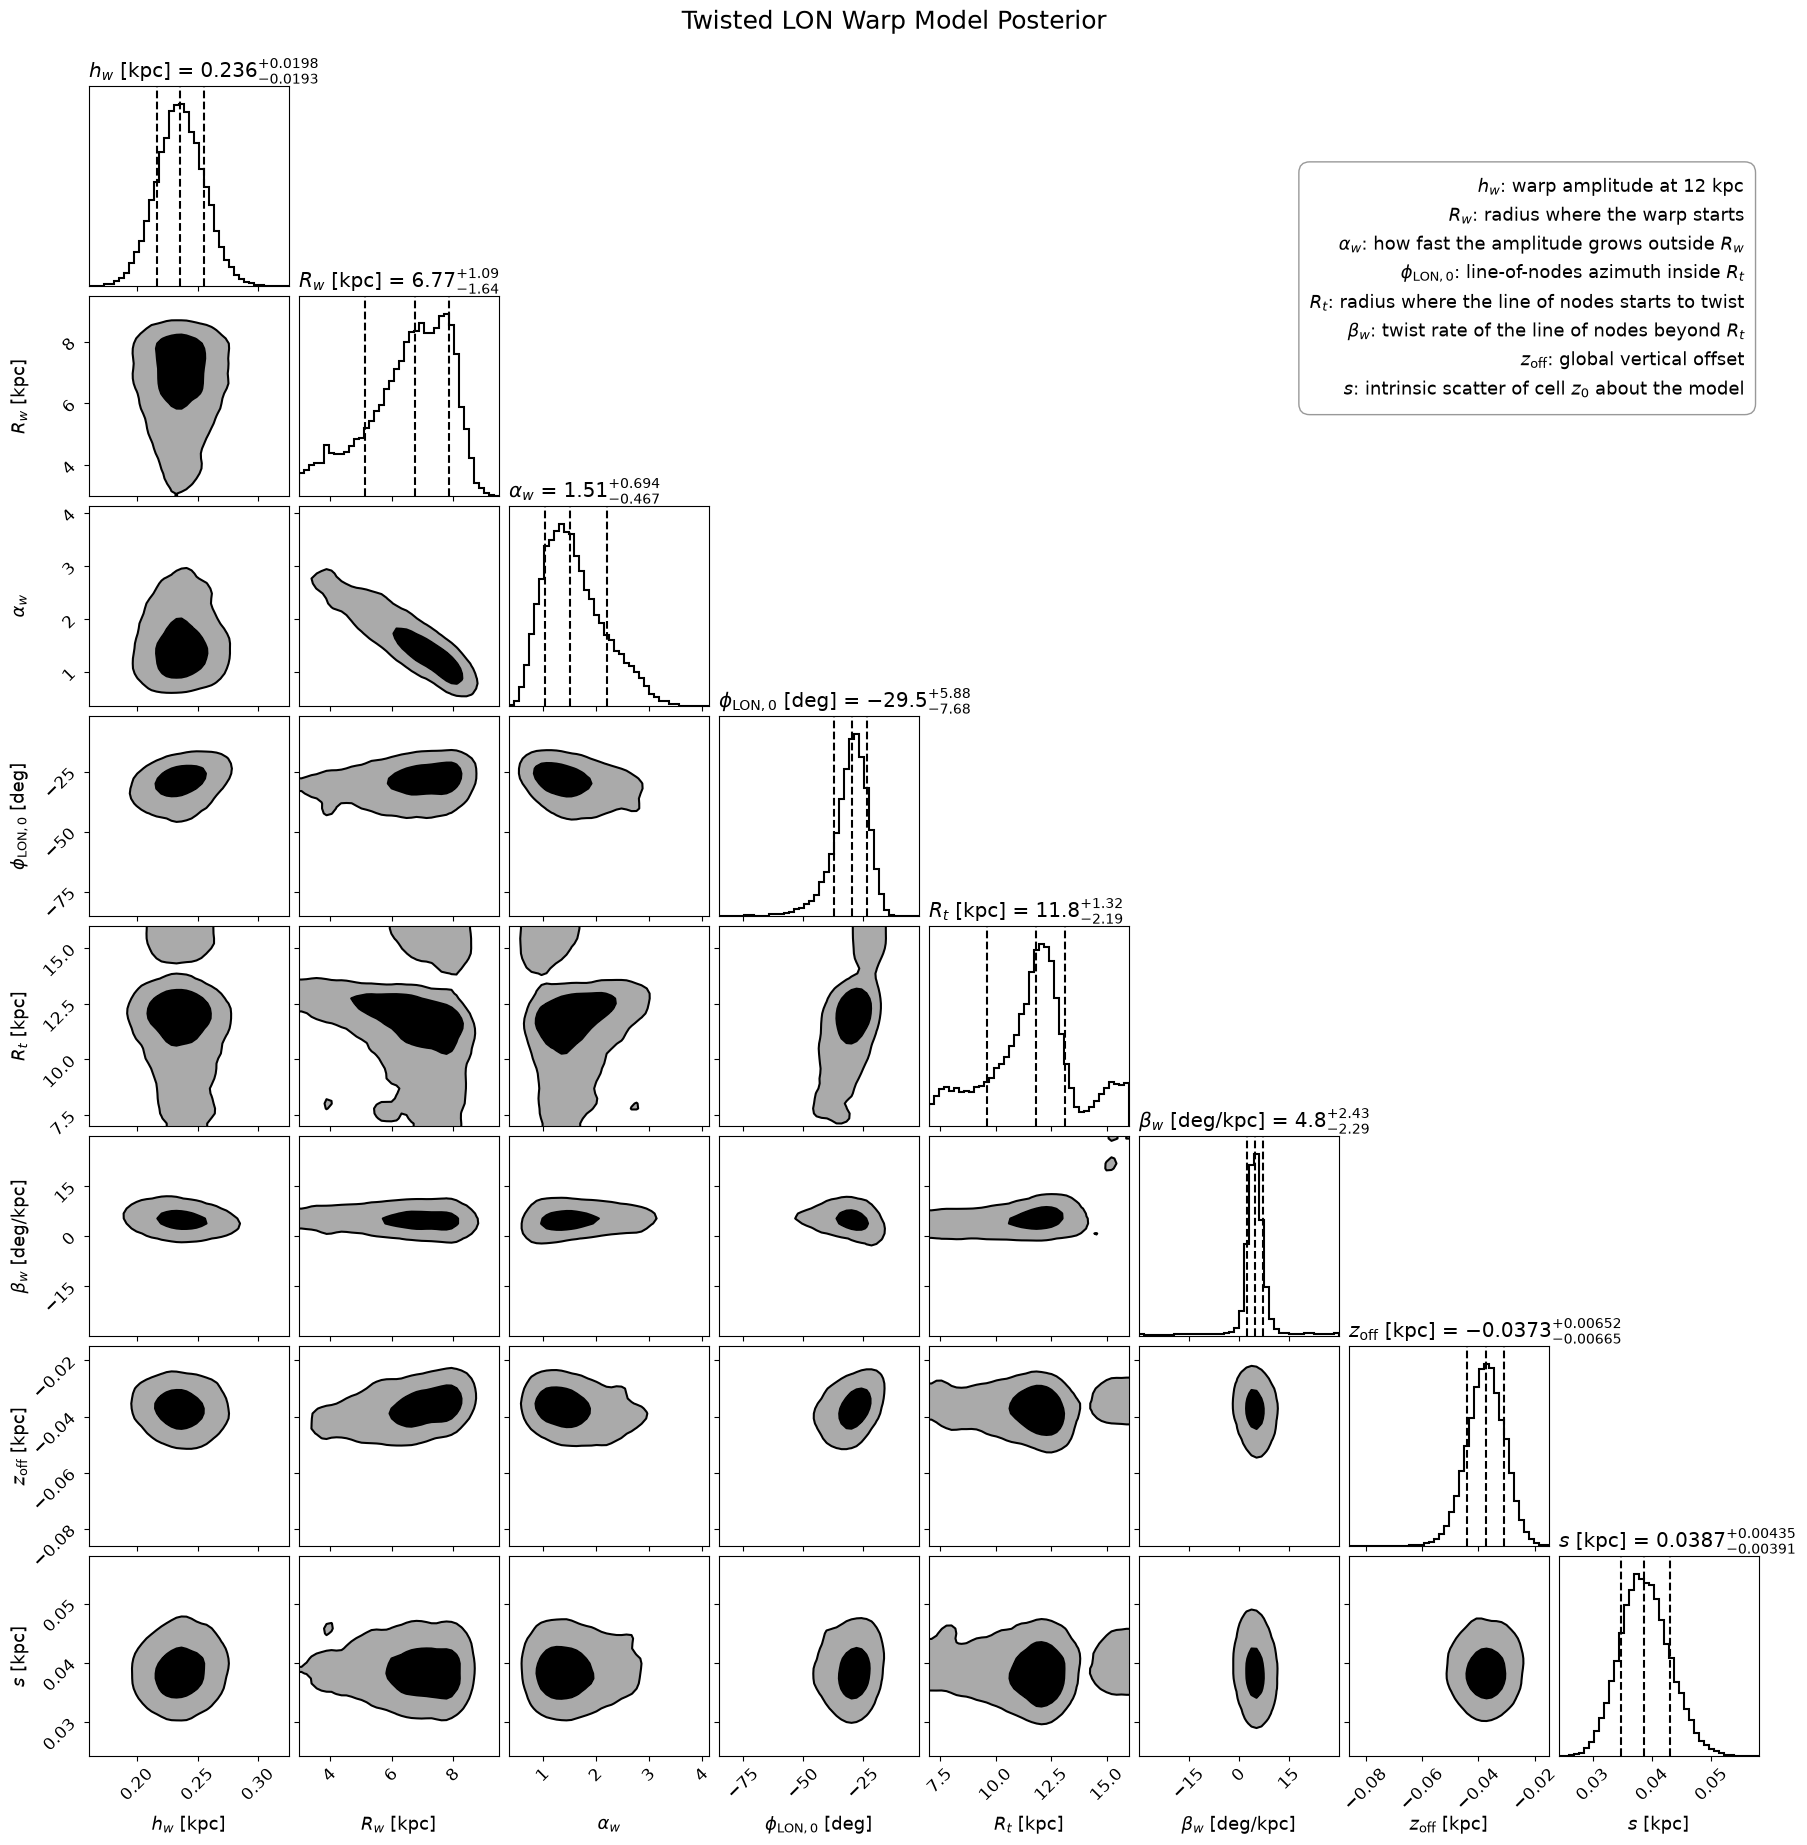

In [22]:
# --- parameter summary, with Poggio young giants for comparison ---
pg = other_measurements["Poggio young giants"]

def summarize_warp(samples, label):
    print(f"\n{label}")
    print(f"{'parameter':<10s} {'median':>9s} {'-1sig':>8s} {'+1sig':>8s} {'Poggio YG':>10s}")
    rows = dict(samples)
    rows["h_w0"] = poggio_h_w0(samples)          # amplitude in Poggio's definition
    for k in ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w", "z_off", "s"]:
        if k not in rows:
            continue
        lo, med, hi = np.percentile(rows[k], [16, 50, 84])
        ref = f"{pg[k]:>10.3g}" if k in pg else f"{'':>10s}"
        print(f"{k:<10s} {med:>9.3f} {med - lo:>8.3f} {hi - med:>8.3f} {ref}")

summarize_warp(samples_twist, "twisted line of nodes")

# --- twisted corner plot with title and parameter legend ---
labels_map["h_w0"] = r"$h_{w}\ [{\rm kpc}]$"
names = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w", "z_off", "s"]

fig_t = corner_plot(samples_twist, names=names)
fig_t.suptitle("Twisted LON Warp Model Posterior", fontsize=18, y=1.02)

legend_text = "\n".join([
    r"$h_w$: warp amplitude at 12 kpc",
    r"$R_w$: radius where the warp starts",
    r"$\alpha_w$: how fast the amplitude grows outside $R_w$",
    r"$\phi_{\rm LON,0}$: line-of-nodes azimuth inside $R_t$",
    r"$R_t$: radius where the line of nodes starts to twist",
    r"$\beta_w$: twist rate of the line of nodes beyond $R_t$",
    r"$z_{\rm off}$: global vertical offset",
    r"$s$: intrinsic scatter of cell $z_0$ about the model",
])
fig_t.text(0.97, 0.93, legend_text, ha="right", va="top", fontsize=13, linespacing=1.6,
           bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="0.6"))

fig_t.savefig(FIG_DIR / "warp_corner_twist.png", dpi=200, bbox_inches="tight")
fig_t.savefig(FIG_DIR / "warp_corner_twist.pdf", bbox_inches="tight")
plt.show()

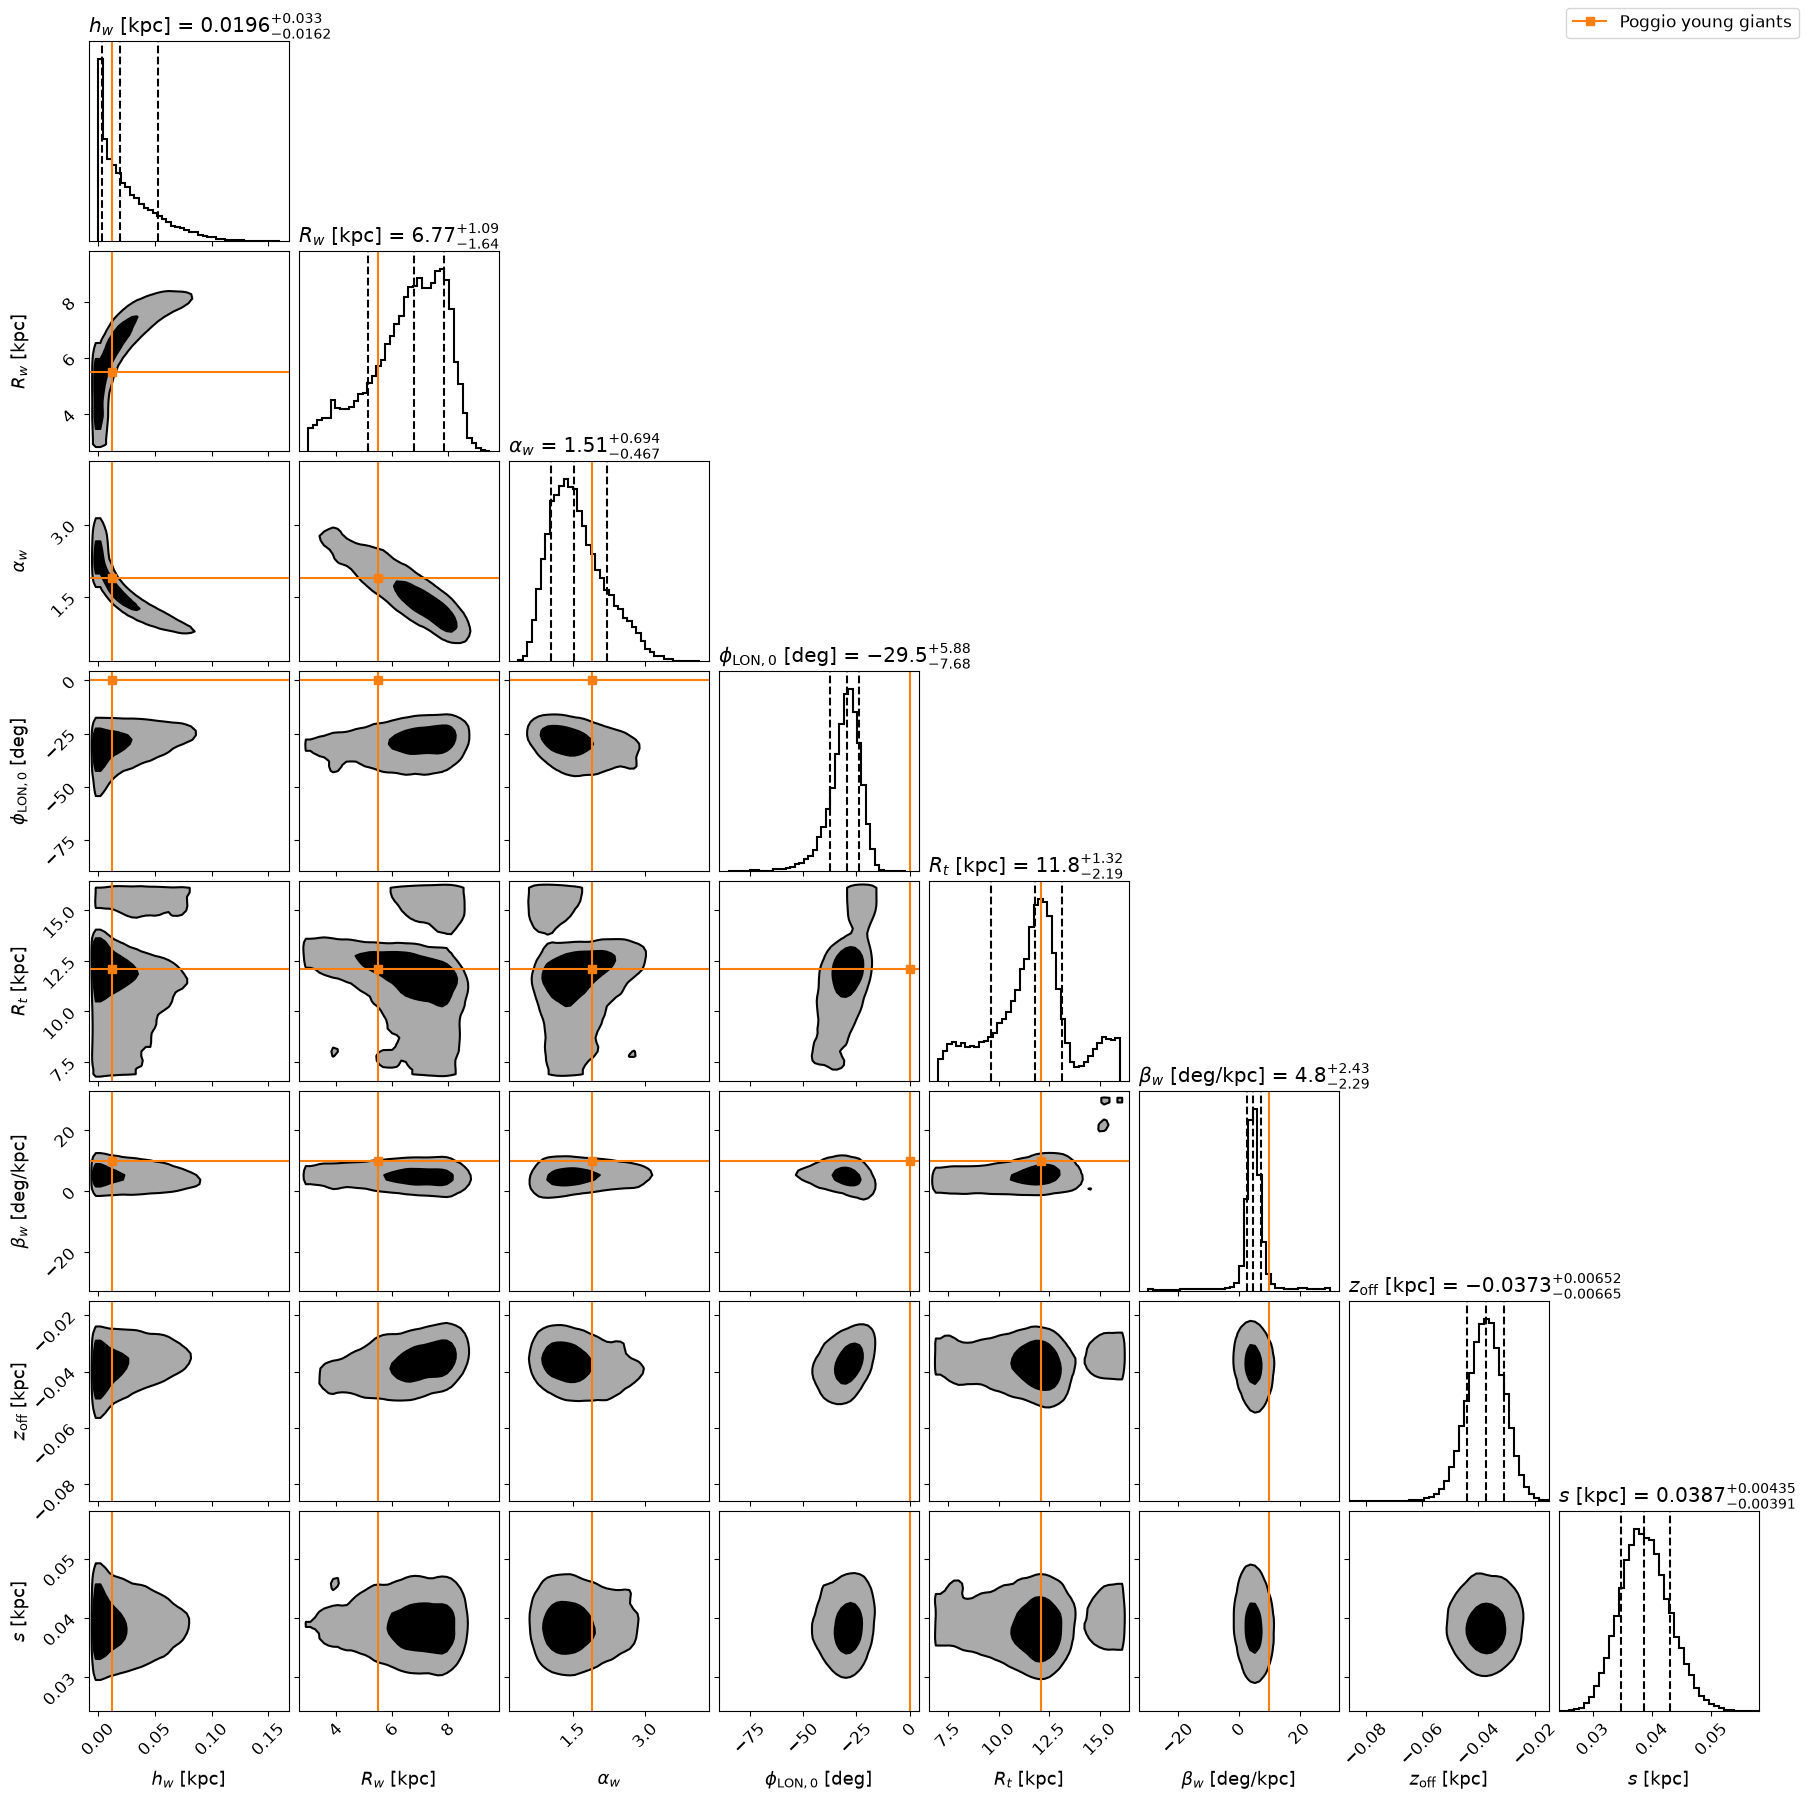

In [23]:
from matplotlib.lines import Line2D

pg = other_measurements["Poggio young giants"]
POG_COLOR = "tab:orange"

def corner_with_poggio(samples, names):
    s = dict(samples)
    s["h_w0"] = np.asarray(poggio_h_w0(samples))     # Poggio definition, so the axes match
    fig = corner_plot(s, names=names)

    truth = np.array([pg.get(k, np.nan) for k in names], float)
    n = len(names)
    axes = np.array(fig.axes).reshape(n, n)

    # Poggio lines and squares
    for i in range(n):
        for j in range(i + 1):
            ax = axes[i, j]
            if np.isfinite(truth[j]):
                ax.axvline(truth[j], color=POG_COLOR, lw=1.5)
            if i != j and np.isfinite(truth[i]):
                ax.axhline(truth[i], color=POG_COLOR, lw=1.5)
            if i != j and np.isfinite(truth[i]) and np.isfinite(truth[j]):
                ax.plot(truth[j], truth[i], "s", color=POG_COLOR, ms=6, zorder=10)

    # widen axes so the Poggio value is always visible
    for k in range(n):
        if not np.isfinite(truth[k]):
            continue
        lo, hi = axes[n - 1, k].get_xlim() if k < n - 1 else axes[k, k].get_xlim()
        lo, hi = min(lo, truth[k]), max(hi, truth[k])
        pad = 0.05 * (hi - lo)
        lim = (lo - pad, hi + pad)
        for r in range(k, n):          # column k: x axis
            axes[r, k].set_xlim(lim)
        for c in range(0, k):          # row k: y axis
            axes[k, c].set_ylim(lim)

    fig.legend(handles=[Line2D([], [], color=POG_COLOR, marker="s", label="Poggio young giants")],
               loc="upper right", fontsize=12)
    return fig

names_twist = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w", "z_off", "s"]

fig_t = corner_with_poggio(samples_twist, names_twist)
# fig_t.savefig(FIG_DIR / "warp_corner_twist_poggio.png", dpi=200, bbox_inches="tight")
# fig_t.savefig(FIG_DIR / "warp_corner_twist_poggio.pdf", bbox_inches="tight")
plt.show()

{'R_w': 5.5, 'phiLON0': 0.1, 'beta_w': 9.9}


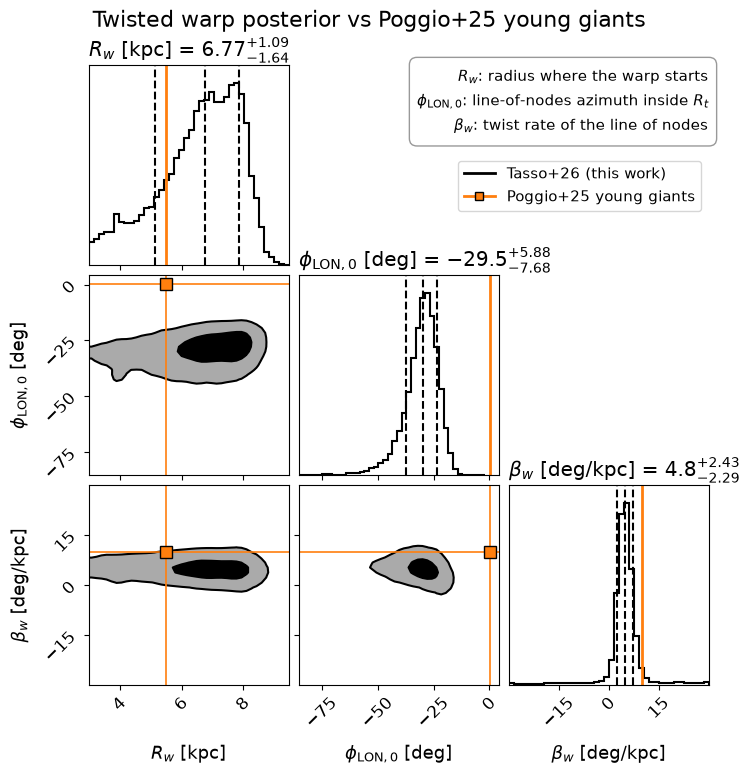

In [24]:
from matplotlib.lines import Line2D

# --- compact corner plot: twisted fit vs Poggio+25 young giants ---
names_c = ["R_w", "phiLON0", "beta_w"]

pg = other_measurements["Poggio young giants"]
ref = {k: pg[k] for k in names_c}
print(ref)

fig_c = corner_plot(samples_twist, names=names_c)
n = len(names_c)
ax_c = np.array(fig_c.axes).reshape(n, n)
ORANGE = "tab:orange"

# widen limits so the reference values are visible
lims = {}
for j, k in enumerate(names_c):
    lo, hi = ax_c[n - 1, j].get_xlim()
    pad = 0.05 * (hi - lo)
    lims[k] = (min(lo, ref[k] - pad), max(hi, ref[k] + pad))
for j, k in enumerate(names_c):
    for i in range(j, n):
        ax_c[i, j].set_xlim(lims[k])
for i in range(1, n):
    for j in range(i):
        ax_c[i, j].set_ylim(lims[names_c[i]])

# overlay the reference values
for i, ki in enumerate(names_c):
    ax_c[i, i].axvline(ref[ki], color=ORANGE, lw=2)
    for j in range(i):
        kj = names_c[j]
        ax_c[i, j].axvline(ref[kj], color=ORANGE, lw=1.2)
        ax_c[i, j].axhline(ref[ki], color=ORANGE, lw=1.2)
        ax_c[i, j].plot(ref[kj], ref[ki], "s", color=ORANGE, ms=8, mec="k", zorder=6)

fig_c.suptitle("Twisted warp posterior vs Poggio+25 young giants", fontsize=16, y=1.02)

desc = "\n".join([
    r"$R_w$: radius where the warp starts",
    r"$\phi_{\rm LON,0}$: line-of-nodes azimuth inside $R_t$",
    r"$\beta_w$: twist rate of the line of nodes",
])
# place both boxes in the empty top row, right-aligned with the last panel column
pos0 = ax_c[0, 0].get_position()
x_right = ax_c[n - 1, n - 1].get_position().x1
y_top = pos0.y1
y_mid = pos0.y0 + 0.56 * pos0.height
fig_c.text(x_right, y_top, desc, ha="right", va="top", fontsize=11, linespacing=1.6,
           bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="0.6"))

handles = [Line2D([0], [0], color="k", lw=2, label="Tasso+26 (this work)"),
           Line2D([0], [0], color=ORANGE, marker="s", mec="k", lw=2, label="Poggio+25 young giants")]
fig_c.legend(handles=handles, loc="upper right", bbox_to_anchor=(x_right, y_mid),
             fontsize=11, frameon=True)
fig_c.savefig(FIG_DIR / "warp_corner_compact_vs_poggio.png", dpi=200, bbox_inches="tight")
fig_c.savefig(FIG_DIR / "warp_corner_compact_vs_poggio.pdf", bbox_inches="tight")
plt.show()

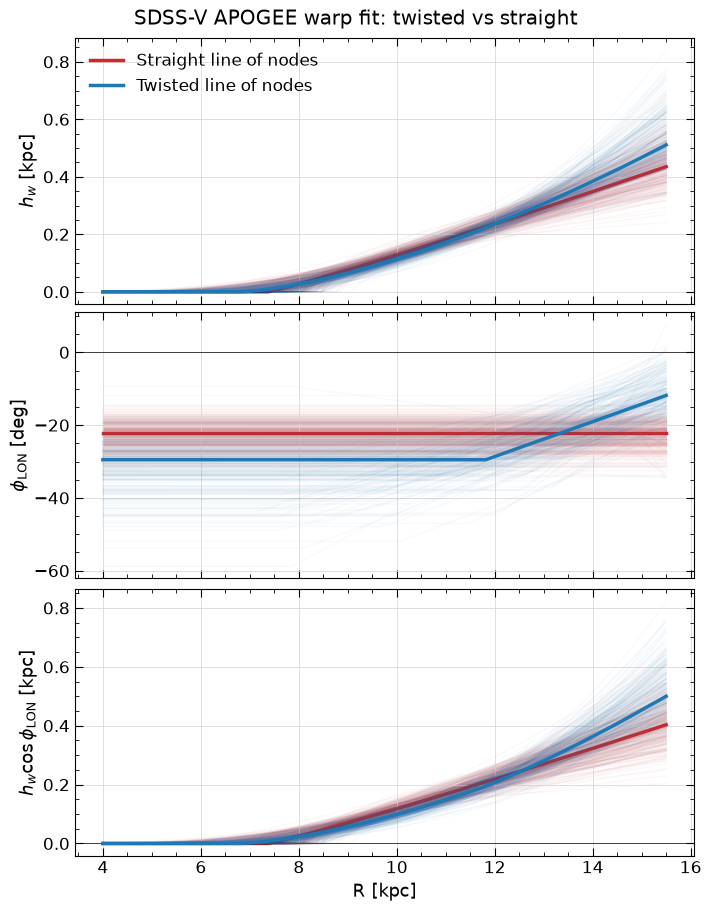

In [25]:
rng = np.random.default_rng(0)
R_grid = np.linspace(4.0, 15.5, 400)
N_DRAWS = 250

def warp_profiles(samples, R, twisted):
    keys = ["R_w", "alpha_w", "phiLON0", "h_w0"] + (["R_t", "beta_w"] if twisted else [])
    p = {k: np.asarray(samples[k]).reshape(-1, 1) for k in keys}
    A, phi = warp_amp_phase(R[None, :], **p)
    A = np.asarray(A)
    phi = np.asarray(phi) + 0.0 * A
    return A, phi

def three_curves(A, phi):
    return [A, phi, A * np.cos(np.radians(phi))]     # h_w, phi_LON, h_w cos(phi_LON)

fits = {"Straight line of nodes": (samples_notwist, False, "tab:red", 1),
        "Twisted line of nodes":  (samples_twist,   True,  "tab:blue", 3)}

fig, axes = plt.subplots(3, 1, figsize=(7, 9), sharex=True, constrained_layout=True)
for label, (samp, twisted, color, z) in fits.items():
    # random posterior draws (each has its own kinks)
    A, phi = warp_profiles(samp, R_grid, twisted)
    idx = rng.choice(A.shape[0], N_DRAWS, replace=False)
    draws = three_curves(A[idx], phi[idx])
    # model at the median parameters (keeps sharp kinks)
    med = {k: np.array([np.median(v)]) for k, v in samp.items()}
    A_m, phi_m = warp_profiles(med, R_grid, twisted)
    medians = three_curves(A_m[0], phi_m[0])

    for ax, d, m in zip(axes, draws, medians):
        ax.plot(R_grid, d.T, color=color, alpha=0.03, lw=1, zorder=z)
        ax.plot(R_grid, m, color=color, lw=2.5, label=label, zorder=z + 1)
        
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[1].set_ylabel(r"$\phi_{\rm LON}$ [deg]")
axes[2].set_ylabel(r"$h_w \cos\phi_{\rm LON}$ [kpc]")
axes[2].set_xlabel("R [kpc]")
for ax in axes[1:]:
    ax.axhline(0, color="k", lw=0.5)
axes[0].legend(frameon=False, loc="upper left")
from matplotlib.ticker import AutoMinorLocator

for ax in axes:
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which="major", length=6, direction="in", top=True, right=True)
    ax.tick_params(which="minor", length=3, direction="in", top=True, right=True)
    ax.grid(which="major", color="0.85", linestyle="-", linewidth=0.6, zorder=0)
fig.suptitle("SDSS-V APOGEE warp fit: twisted vs straight")
fig.savefig(FIG_DIR / "warp_profiles_twist_vs_straight.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG_DIR / "warp_profiles_twist_vs_straight.pdf", bbox_inches="tight")
plt.show()

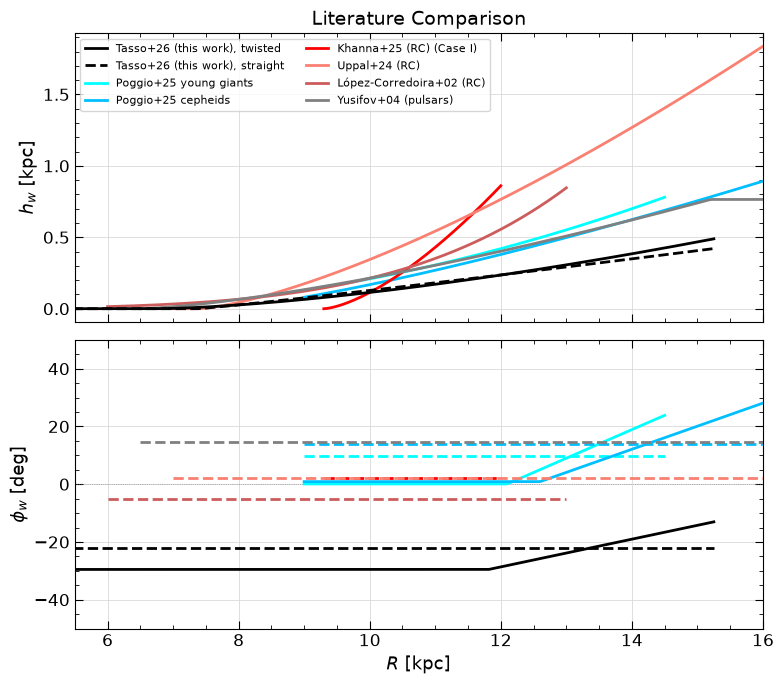

In [26]:
from matplotlib.ticker import AutoMinorLocator

# ---------- this work: median-parameter models from the new NUTS fits ----------
def model_curves(samples, R, twisted):
    keys = ["R_w", "alpha_w", "phiLON0", "h_w0"] + (["R_t", "beta_w"] if twisted else [])
    p = {k: np.array([np.median(samples[k])]) for k in keys}
    A, phi = warp_amp_phase(R[None, :], **p)
    A = np.asarray(A)[0]
    return A, np.asarray(phi)[0] + 0.0 * A

R_grid_mine = np.linspace(warp_data["R"].min(), warp_data["R"].max(), 400)
hw_mine_twisted,  phi_mine_twisted  = model_curves(samples_twist,   R_grid_mine, True)
hw_mine_straight, phi_mine_straight = model_curves(samples_notwist, R_grid_mine, False)

# ---------- literature (unchanged from the earlier comparison) ----------
def h_w_paper(R, R_w, h_w0, alpha_w):
    return np.where(R > R_w, h_w0 * np.clip(R - R_w, 0, None)**alpha_w, 0.0)

def phiLON_paper(R, phiLON0, R_t, beta_w):
    return np.where(R <= R_t, phiLON0, phiLON0 + beta_w * (R - R_t))

def A_rc_paper(R, h_w0, R_w, alpha_w):
    return h_w0 * np.clip(R - R_w, 0, None)**alpha_w

def A_uppal(R, C_w=0.0057, R_w=7.4, eps_w=1.40):
    return C_w * np.clip(R * 1000.0 - R_w * 1000.0, 0, None)**eps_w / 1000.0

def A_lopez(R, C_w=1.2e-3, exp=5.25):
    return C_w * np.clip(R, 0, None)**exp / 1000.0

def A_yusifov(R, C_w=37.0, R_w=6.5, b_w=1.4, R_WS=15.2):
    return C_w * np.clip(np.minimum(R, R_WS) - R_w, 0, None)**b_w / 1000.0

yg   = dict(R_w=5.5, h_w0=0.012, alpha_w=1.9, phiLON0=0.1, R_t=12.1, beta_w=9.9)
ceph = dict(R_w=7.7, h_w0=0.057, alpha_w=1.3, phiLON0=0.9, R_t=12.6, beta_w=8.0)
yg_straight_phiLON, ceph_straight_phiLON = 9.9, 14.0
khanna  = dict(h_w0=0.194, R_w=9.30, alpha_w=1.5, phiLON0=2.0)                 # Case I
uppal   = dict(C_w=0.0057, R_w=7.4, eps_w=1.40, phiLON0=2.03)
lopez   = dict(C_w=1.2e-3, exp=5.25, phiLON0=-5.0)
yusifov = dict(C_w=37.0, R_w=6.5, b_w=1.4, R_WS=15.2, phiLON0=14.5)           # sign-flipped

R_grid_yg    = np.linspace(9.0, 14.5, 300)
R_grid_ceph  = np.linspace(9.0, 16.5, 300)
R_grid_rc1   = np.linspace(9.30, 12.0, 300)
R_grid_uppal = np.linspace(7.0, 16.0, 300)
R_grid_lopez = np.linspace(6.0, 13.0, 300)
R_grid_yus   = np.linspace(6.5, 20.0, 300)

hw_yg    = h_w_paper(R_grid_yg, yg["R_w"], yg["h_w0"], yg["alpha_w"])
hw_ceph  = h_w_paper(R_grid_ceph, ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])
hw_rc1   = A_rc_paper(R_grid_rc1, khanna["h_w0"], khanna["R_w"], khanna["alpha_w"])
hw_uppal = A_uppal(R_grid_uppal, uppal["C_w"], uppal["R_w"], uppal["eps_w"])
hw_lopez = A_lopez(R_grid_lopez, lopez["C_w"], lopez["exp"])
hw_yus   = A_yusifov(R_grid_yus, yusifov["C_w"], yusifov["R_w"], yusifov["b_w"], yusifov["R_WS"])

phi_yg_twisted   = phiLON_paper(R_grid_yg, yg["phiLON0"], yg["R_t"], yg["beta_w"])
phi_yg_straight  = np.full_like(R_grid_yg, yg_straight_phiLON)
phi_ceph_twisted = phiLON_paper(R_grid_ceph, ceph["phiLON0"], ceph["R_t"], ceph["beta_w"])
phi_ceph_straight = np.full_like(R_grid_ceph, ceph_straight_phiLON)

# ---------- figure ----------
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

axes[0].plot(R_grid_mine, hw_mine_twisted,  color="black", lw=2, ls="-",  zorder=4, label="Tasso+26 (this work), twisted")
axes[0].plot(R_grid_mine, hw_mine_straight, color="black", lw=2, ls="--", zorder=4, label="Tasso+26 (this work), straight")
axes[0].plot(R_grid_yg,    hw_yg,    color="cyan",        lw=2, zorder=3, label="Poggio+25 young giants")
axes[0].plot(R_grid_ceph,  hw_ceph,  color="deepskyblue", lw=2, zorder=3, label="Poggio+25 cepheids")
axes[0].plot(R_grid_rc1,   hw_rc1,   color="red",         lw=2, zorder=3, label="Khanna+25 (RC) (Case I)")
axes[0].plot(R_grid_uppal, hw_uppal, color="salmon",      lw=2, zorder=3, label="Uppal+24 (RC)")
axes[0].plot(R_grid_lopez, hw_lopez, color="indianred",   lw=2, zorder=3, label="López-Corredoira+02 (RC)")
axes[0].plot(R_grid_yus,   hw_yus,   color="gray",        lw=2, zorder=3, label="Yusifov+04 (pulsars)")
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=8, ncol=2)

axes[1].plot(R_grid_mine, phi_mine_twisted,  color="black", lw=2, ls="-",  zorder=4)
axes[1].plot(R_grid_mine, phi_mine_straight, color="black", lw=2, ls="--", zorder=4)
axes[1].plot(R_grid_yg,    phi_yg_twisted,    color="cyan",        lw=2, ls="-",  zorder=3)
axes[1].plot(R_grid_yg,    phi_yg_straight,   color="cyan",        lw=2, ls="--", zorder=3)
axes[1].plot(R_grid_ceph,  phi_ceph_twisted,  color="deepskyblue", lw=2, ls="-",  zorder=3)
axes[1].plot(R_grid_ceph,  phi_ceph_straight, color="deepskyblue", lw=2, ls="--", zorder=3)
axes[1].plot(R_grid_rc1,   np.full_like(R_grid_rc1,   khanna["phiLON0"]),  color="red",       lw=2, ls="--", zorder=3)
axes[1].plot(R_grid_uppal, np.full_like(R_grid_uppal, uppal["phiLON0"]),   color="salmon",    lw=2, ls="--", zorder=3)
axes[1].plot(R_grid_lopez, np.full_like(R_grid_lopez, lopez["phiLON0"]),   color="indianred", lw=2, ls="--", zorder=3)
axes[1].plot(R_grid_yus,   np.full_like(R_grid_yus,   yusifov["phiLON0"]), color="gray",      lw=2, ls="--", zorder=3)
axes[1].axhline(0, color="gray", lw=0.5, ls=":")
axes[1].set_ylabel(r"$\phi_w$ [deg]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 16)
axes[1].set_ylim(-50, 50)

for ax in axes:
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which="major", length=6, direction="in", top=True, right=True)
    ax.tick_params(which="minor", length=3, direction="in", top=True, right=True)
    ax.grid(which="major", color="0.85", linestyle="-", linewidth=0.6, zorder=0)

axes[0].set_title("Literature Comparison", fontsize=14)
plt.tight_layout()
fig.savefig(FIG_DIR / "lon_amplitude_comparison_new.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "lon_amplitude_comparison_new.png", dpi=200, bbox_inches="tight")
plt.show()

h_w0
  off axis, not drawn: López-Corredoira+02 (RC) = 0.556
  off axis, not drawn: Khanna+25 (RC) = 0.861
  off axis, not drawn: Uppal+24 (RC) = 0.765
R_w
alpha_w
phiLON0
R_t
beta_w


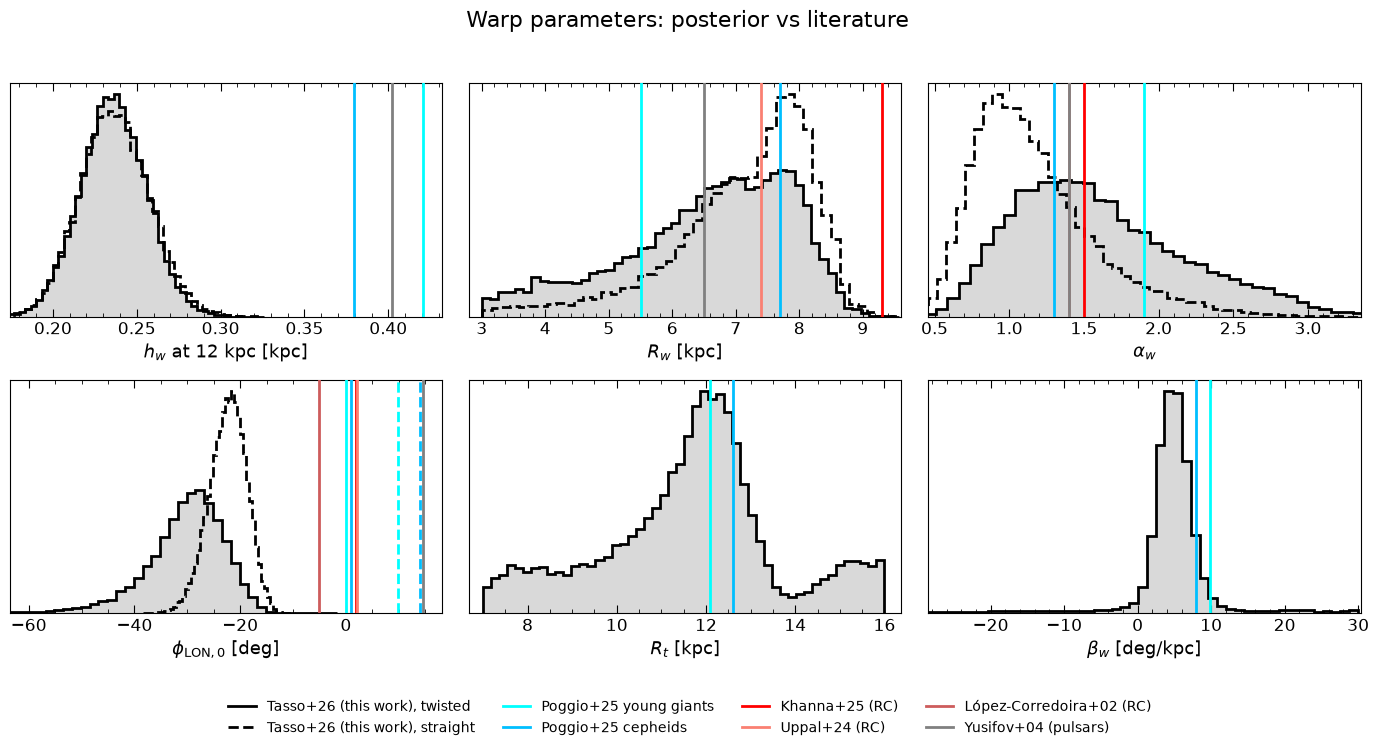

In [27]:
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator

# ---------- literature values for each panel ----------
LIT_COLORS = {"Poggio+25 young giants": "cyan", "Poggio+25 cepheids": "deepskyblue",
              "Khanna+25 (RC)": "red", "Uppal+24 (RC)": "salmon",
              "López-Corredoira+02 (RC)": "indianred", "Yusifov+04 (pulsars)": "gray"}

lit = {
    # amplitude evaluated at 12 kpc, so it matches our h_w parameter (normalized at 12 kpc)
    "h_w0": {"Poggio+25 young giants": float(h_w_paper(np.array(12.0), yg["R_w"], yg["h_w0"], yg["alpha_w"])),
             "Poggio+25 cepheids":     float(h_w_paper(np.array(12.0), ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])),
             "Khanna+25 (RC)":         float(A_rc_paper(12.0, khanna["h_w0"], khanna["R_w"], khanna["alpha_w"])),
             "Uppal+24 (RC)":          float(A_uppal(12.0, uppal["C_w"], uppal["R_w"], uppal["eps_w"])),
             "López-Corredoira+02 (RC)": float(A_lopez(12.0, lopez["C_w"], lopez["exp"])),
             "Yusifov+04 (pulsars)":   float(A_yusifov(12.0, yusifov["C_w"], yusifov["R_w"], yusifov["b_w"], yusifov["R_WS"]))},
    "R_w": {"Poggio+25 young giants": yg["R_w"], "Poggio+25 cepheids": ceph["R_w"],
            "Khanna+25 (RC)": khanna["R_w"], "Uppal+24 (RC)": uppal["R_w"],
            "Yusifov+04 (pulsars)": yusifov["R_w"]},
    # exponent of (R - R_w); Lopez-Corredoira's exponent is on R itself, so it is left out
    "alpha_w": {"Poggio+25 young giants": yg["alpha_w"], "Poggio+25 cepheids": ceph["alpha_w"],
                "Khanna+25 (RC)": khanna["alpha_w"], "Uppal+24 (RC)": uppal["eps_w"],
                "Yusifov+04 (pulsars)": yusifov["b_w"]},
    "phiLON0": {"Poggio+25 young giants": yg["phiLON0"], "Poggio+25 cepheids": ceph["phiLON0"],
                "Khanna+25 (RC)": khanna["phiLON0"], "Uppal+24 (RC)": uppal["phiLON0"],
                "López-Corredoira+02 (RC)": lopez["phiLON0"], "Yusifov+04 (pulsars)": yusifov["phiLON0"]},
    "R_t": {"Poggio+25 young giants": yg["R_t"], "Poggio+25 cepheids": ceph["R_t"]},
    "beta_w": {"Poggio+25 young giants": yg["beta_w"], "Poggio+25 cepheids": ceph["beta_w"]},
}
# straight-line Poggio values (dashed lines)
lit_straight = {"phiLON0": {"Poggio+25 young giants": yg_straight_phiLON,
                            "Poggio+25 cepheids": ceph_straight_phiLON}}

panels = [("h_w0", r"$h_w$ at 12 kpc [kpc]"), ("R_w", r"$R_w$ [kpc]"), ("alpha_w", r"$\alpha_w$"),
          ("phiLON0", r"$\phi_{\rm LON,0}$ [deg]"), ("R_t", r"$R_t$ [kpc]"),
          ("beta_w", r"$\beta_w$ [deg/kpc]")]

def in_range(vals, post, width=2.0):
    """Keep literature values within `width` posterior spans of the posterior."""
    lo, hi = np.percentile(post, [0.5, 99.5]); span = hi - lo
    keep = {k: v for k, v in vals.items() if lo - width * span <= v <= hi + width * span}
    for k in set(vals) - set(keep):
        print(f"  off axis, not drawn: {k} = {vals[k]:.3g}")
    return keep

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (key, xlabel) in zip(axes.ravel(), panels):
    post = np.asarray(samples_twist[key])
    ax.hist(post, bins=50, density=True, histtype="stepfilled", color="0.85", edgecolor="none")
    ax.hist(post, bins=50, density=True, histtype="step", color="black", lw=2, ls="-")
    if key in samples_notwist:
        ax.hist(np.asarray(samples_notwist[key]), bins=50, density=True,
                histtype="step", color="black", lw=2, ls="--")

    print(key)
    keep = in_range(lit[key], post)
    for name, v in keep.items():
        ax.axvline(v, color=LIT_COLORS[name], lw=2, zorder=3)
    keep_s = in_range(lit_straight.get(key, {}), post) if key in lit_straight else {}
    for name, v in keep_s.items():
        ax.axvline(v, color=LIT_COLORS[name], lw=2, ls="--", zorder=3)

    lo, hi = np.percentile(post, [0.5, 99.5])
    allv = [lo, hi] + list(keep.values()) + list(keep_s.values())
    pad = 0.05 * (max(allv) - min(allv))
    ax.set_xlim(min(allv) - pad, max(allv) + pad)
    ax.set_xlabel(xlabel)
    ax.set_yticks([])
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which="major", length=6, direction="in", top=True)
    ax.tick_params(which="minor", length=3, direction="in", top=True)

handles = [Line2D([0], [0], color="black", lw=2, ls="-", label="Tasso+26 (this work), twisted"),
           Line2D([0], [0], color="black", lw=2, ls="--", label="Tasso+26 (this work), straight")]
handles += [Line2D([0], [0], color=c, lw=2, label=n) for n, c in LIT_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=10, frameon=False)
fig.suptitle("Warp parameters: posterior vs literature", fontsize=16)
fig.tight_layout(rect=[0, 0.09, 1, 0.96])

# fig.savefig(FIG_DIR / "warp_posterior_vs_literature.pdf", bbox_inches="tight")
# fig.savefig(FIG_DIR / "warp_posterior_vs_literature.png", dpi=300, bbox_inches="tight")
plt.show()

{'Poggio+25 young giants': 0.42, 'Poggio+25 cepheids': 0.38, 'Khanna+25 (RC)': 0.861, 'Uppal+24 (RC)': 0.765, 'López-Corredoira+02 (RC)': 0.556, 'Yusifov+04 (pulsars)': 0.402}


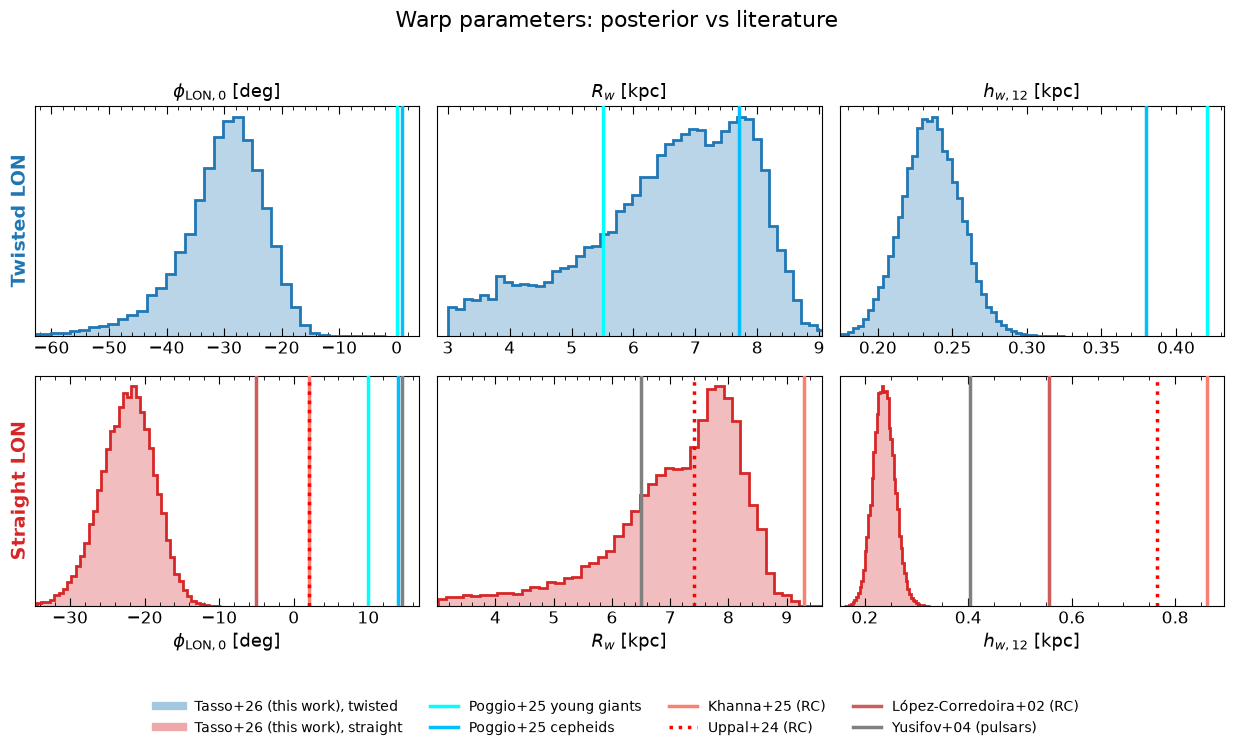

In [28]:
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator

COL = {"Poggio+25 young giants": "cyan", "Poggio+25 cepheids": "deepskyblue",
       "Khanna+25 (RC)": "salmon", "Uppal+24 (RC)": "red",
       "López-Corredoira+02 (RC)": "indianred", "Yusifov+04 (pulsars)": "gray"}
LS = {n: "-" for n in COL}
LS["Uppal+24 (RC)"] = ":"
# ---------- literature amplitude evaluated at 12 kpc ----------
A12 = {"Poggio+25 young giants": float(h_w_paper(np.array(12.0), yg["R_w"], yg["h_w0"], yg["alpha_w"])),
       "Poggio+25 cepheids":     float(h_w_paper(np.array(12.0), ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])),
       "Khanna+25 (RC)":         float(A_rc_paper(12.0, khanna["h_w0"], khanna["R_w"], khanna["alpha_w"])),
       "Uppal+24 (RC)":          float(A_uppal(12.0, uppal["C_w"], uppal["R_w"], uppal["eps_w"])),
       "López-Corredoira+02 (RC)": float(A_lopez(12.0, lopez["C_w"], lopez["exp"])),
       "Yusifov+04 (pulsars)":   float(A_yusifov(12.0, yusifov["C_w"], yusifov["R_w"], yusifov["b_w"], yusifov["R_WS"]))}
print({k: round(v, 3) for k, v in A12.items()})

# ---------- literature by model type ----------
lit_twisted = {   # papers that fit a twisted line of nodes
    "phiLON0": {"Poggio+25 young giants": yg["phiLON0"], "Poggio+25 cepheids": ceph["phiLON0"]},
    "R_w":     {"Poggio+25 young giants": yg["R_w"], "Poggio+25 cepheids": ceph["R_w"]},
    "h_w0":    {"Poggio+25 young giants": A12["Poggio+25 young giants"],
                "Poggio+25 cepheids": A12["Poggio+25 cepheids"]},
}
lit_straight = {  # papers that fit a straight line of nodes
    "phiLON0": {"Poggio+25 young giants": yg_straight_phiLON, "Poggio+25 cepheids": ceph_straight_phiLON,
                "Khanna+25 (RC)": khanna["phiLON0"], "Uppal+24 (RC)": uppal["phiLON0"],
                "López-Corredoira+02 (RC)": lopez["phiLON0"], "Yusifov+04 (pulsars)": yusifov["phiLON0"]},
    "R_w":     {"Khanna+25 (RC)": khanna["R_w"], "Uppal+24 (RC)": uppal["R_w"],
                "Yusifov+04 (pulsars)": yusifov["R_w"]},
    "h_w0":    {k: A12[k] for k in ("Khanna+25 (RC)", "Uppal+24 (RC)",
                                    "López-Corredoira+02 (RC)", "Yusifov+04 (pulsars)")},
}

columns = [("phiLON0", r"$\phi_{\rm LON,0}$ [deg]"), ("R_w", r"$R_w$ [kpc]"),
           ("h_w0", r"$h_{w,12}$ [kpc]")]
rows = [("Twisted LON",  samples_twist,   lit_twisted,  "tab:blue"),
        ("Straight LON", samples_notwist, lit_straight, "tab:red")]

# ---------- figure ----------
fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.5))
for r, (row_label, samp, lit_d, color) in enumerate(rows):
    for c, (key, xlabel) in enumerate(columns):
        ax = axes[r, c]
        post = np.asarray(samp[key])
        ax.hist(post, bins=50, density=True, histtype="stepfilled", color=color, alpha=0.3, edgecolor="none")
        ax.hist(post, bins=50, density=True, histtype="step", color=color, lw=2)

        for name, v in lit_d[key].items():
            ax.axvline(v, color=COL[name], ls=LS[name], lw=2.5, zorder=3)
            
        lo, hi = np.percentile(post, [0.5, 99.5])
        allv = [lo, hi] + list(lit_d[key].values())
        pad = 0.05 * (max(allv) - min(allv))
        ax.set_xlim(min(allv) - pad, max(allv) + pad)
        ax.set_yticks([])
        ax.xaxis.set_minor_locator(AutoMinorLocator())
        ax.tick_params(which="major", length=6, direction="in", top=True)
        ax.tick_params(which="minor", length=3, direction="in", top=True)
        if r == 1:
            ax.set_xlabel(xlabel)
        else:
            ax.set_title(xlabel, fontsize=13)
        if c == 0:
            ax.set_ylabel(row_label, fontsize=14, color=color, fontweight="bold")

handles = [Line2D([0], [0], color="tab:blue", lw=6, alpha=0.4, label="Tasso+26 (this work), twisted"),
           Line2D([0], [0], color="tab:red", lw=6, alpha=0.4, label="Tasso+26 (this work), straight")]
handles += [Line2D([0], [0], color=COL[n], ls=LS[n], lw=2.5, label=n) for n in COL]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=10, frameon=False)
fig.suptitle("Warp parameters: posterior vs literature", fontsize=16)
fig.tight_layout(rect=[0, 0.10, 1, 0.96])

fig.savefig(FIG_DIR / "warp_posterior_vs_literature.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "warp_posterior_vs_literature.png", dpi=300, bbox_inches="tight")
plt.show()

residual: median -0.005
saved /Users/emmatasso/outerdisk/figures/z0_data_model_residual.pdf and .png


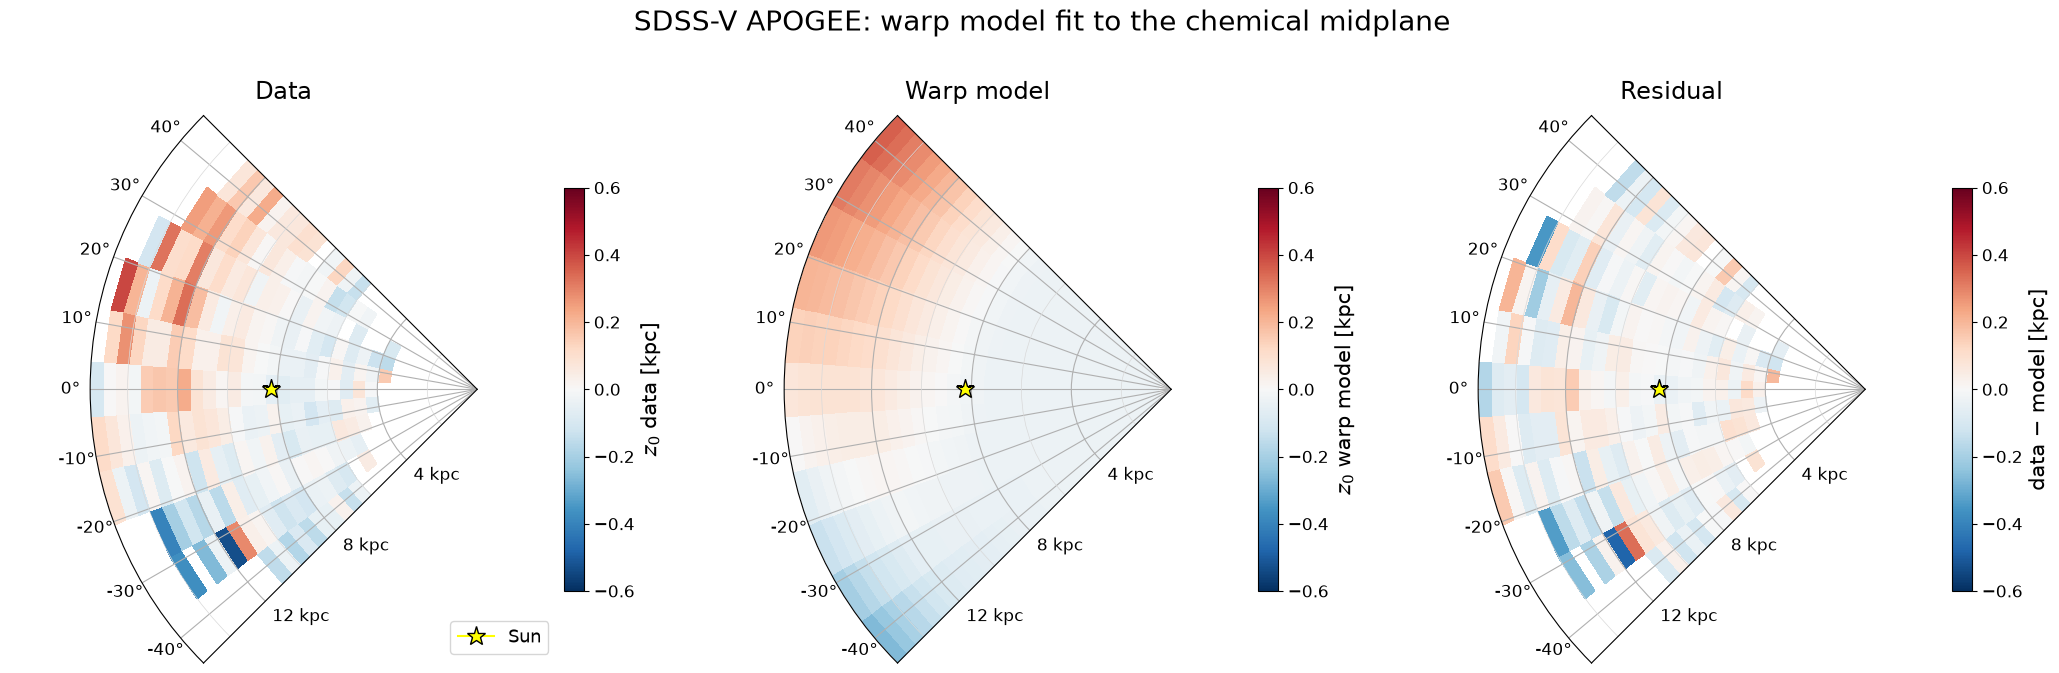

In [30]:
# =============================================================================
# Data z0 heatmap | warp model | residual (data - model), same wedge and bins
# =============================================================================
SAMPLES_USED       = samples_twist      # or samples_notwist
TWISTED            = True               # must match SAMPLES_USED
MASK_MODEL_TO_DATA = False              # True: only show the model in cells that have data
RES_LIM            = .6               # residual color range (+/-); None = 98th percentile of |residual|
OUT_STEM_RESID     = FIG_DIR / "z0_data_model_residual"

# ---- model on the same grid (cell centers; columns ascend in theta like z0_plot) ----
R_cen     = 0.5 * (R_edges[:-1] + R_edges[1:])
theta_cen = 0.5 * (theta_edges[:-1] + theta_edges[1:])            # radians, Sun at 0, clockwise
R2d, T2d  = np.meshgrid(R_cen, theta_cen, indexing="ij")          # shape (n_R, n_theta)

keys = warp_param_names if TWISTED else [k for k in warp_param_names if k not in ("R_t", "beta_w")]
p_med = {k: float(np.median(SAMPLES_USED[k])) for k in keys}
p_med["z_off"] = float(np.median(SAMPLES_USED["z_off"]))
model_grid = np.asarray(z_model(R2d, T2d, p_med))

data_grid  = np.asarray(z0_plot, dtype=float)
have_data  = np.isfinite(data_grid)
resid_grid = np.where(have_data, data_grid - model_grid, np.nan)
if MASK_MODEL_TO_DATA:
    model_grid = np.where(have_data, model_grid, np.nan)

r_use = resid_grid[np.isfinite(resid_grid)]
if RES_LIM is None:
    RES_LIM = float(np.nanpercentile(np.abs(r_use), 98))
print(f"residual: median {np.median(r_use):+.3f}")

# ---- figure ----
fig, axes = plt.subplots(1, 3, figsize=(21, 7), subplot_kw=dict(projection="polar"))
panels = [
    (axes[0], data_grid,  "RdBu_r", -ZLIM,    ZLIM,    r"$z_0$ data [kpc]",             "Data"),
    (axes[1], model_grid, "RdBu_r", -ZLIM,    ZLIM,    r"$z_0$ warp model [kpc]",       "Warp model"),
    (axes[2], resid_grid, "RdBu_r", -RES_LIM, RES_LIM, r"data $-$ model [kpc]",         "Residual"),
]
for ax, grid, cmap, vmin, vmax, clabel, title in panels:
    pcm = ax.pcolormesh(T_mesh, R_mesh, np.ma.masked_invalid(grid),
                        cmap=cmap, vmin=vmin, vmax=vmax, shading="flat")
    fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(clabel, fontsize=15)
    ax.set_theta_zero_location("W"); ax.set_theta_direction(-1)
    ax.set_rmax(R_edges[-1])
    ax.set_thetamin(np.degrees(theta_edges[0])); ax.set_thetamax(np.degrees(theta_edges[-1]))
    ax.set_rgrids(R_TICKS, labels=[f"{r} kpc" for r in R_TICKS], fontsize=11)
    ax.set_yticks(EXTRA_R_TICKS, minor=True)
    ax.yaxis.grid(True, which="minor", color="0.85", linestyle="-", linewidth=0.5)
    ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
            markeredgecolor="k", zorder=5, label="Sun")
    ax.set_title(title, fontsize=17, pad=12)
axes[0].legend(loc="lower right", fontsize=13)

fig.suptitle("SDSS-V APOGEE: warp model fit to the chemical midplane", fontsize=20, y=0.98)

fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(OUT_STEM_RESID.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_RESID.with_suffix(".png"), dpi=300, bbox_inches="tight")
print(f"saved {OUT_STEM_RESID}.pdf and .png")
plt.show()